# Upload cropped volume and meshes to analyze wall heterogenity
Loads a `.vti`/`.vtr` reconstruction, crops the z-stack to the true material thickness (symmetric around a known center voxel), and plots the center-y slice (Mz contrast) before/after to verify the crop landed on the right region.

In [121]:
# --- Cell: imports ---
import os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import sys
sys.path.append('.')  # folder containing vti_magnetic_import.py
from vti_magnetic_import import load_vti_sample, inspect_vti



from scipy.ndimage import gaussian_filter, map_coordinates
from skimage.measure import marching_cubes
import pyvista as pv

import matplotlib.ticker as mticker
import pandas as pd

import json

import Functions_3D as vis


# Load the volume

In [122]:
def load_volume_analysis(save_dir, sample_name, date, smooth):
    """
    Load back everything saved by save_volume_analysis: cropped volume,
    smoothed volume (if present), and all derived-field dicts, fully
    reconstructed including their non-array metadata (shape, spacing, etc).

    Returns
    -------
    cropped : dict
    volume_smoothed : dict or None
    fields : dict of dict
        e.g. fields['jacobian'], fields['curl'], fields['divergence'], etc.,
        each reconstructed as a full dict just like the original.
    metadata : dict
        Top-level metadata, useful for provenance/sanity checks.
    """
    meta_path = os.path.join(save_dir, f'{sample_name}_volume_analysis_metadata_{date}.json')
    with open(meta_path) as f:
        metadata = json.load(f)

    if smooth: 
        # --- Smoothed volume, if it was saved ---
        smoothed_path = os.path.join(save_dir, f'{sample_name}_smoothed_{date}.npz')
        volume = None
        if os.path.exists(smoothed_path):
            smoothed_npz = np.load(smoothed_path)
            volume = {
                'Mx': smoothed_npz['Mx'], 'My': smoothed_npz['My'], 'Mz': smoothed_npz['Mz'],
                'magnitude': smoothed_npz['magnitude'],
                'shape': tuple(smoothed_npz['shape']),
                'sigma': metadata.get('sigma'),
            }

    else:

        cropped_npz = np.load(os.path.join(save_dir, f'{sample_name}_volume_{date}.npz'))
        volume = {
            'Mx': cropped_npz['Mx'], 'My': cropped_npz['My'], 'Mz': cropped_npz['Mz'],
            'magnitude': cropped_npz['magnitude'],
            'shape': tuple(cropped_npz['shape']),
        }


    # --- Each derived-field dict ---
    fields = {}
    for field_name in metadata.get('saved_fields', []):
        field_path = os.path.join(save_dir, f'{sample_name}_{field_name}_{date}.npz')
        field_npz = np.load(field_path)
        field_dict = {key: field_npz[key] for key in field_npz.files}
        field_meta = metadata.get(f'{field_name}_meta', {})
        for k, v in field_meta.items():
            field_dict[k] = tuple(v) if isinstance(v, list) else v
        fields[field_name] = field_dict

    return volume, fields, metadata

In [123]:
sample_names = ['452', '270', '105', '665'] 
dates = ['14AUG26_interpolated', '14AUG26_interpolated', '22AUG26_interpolated', '22AUG26_interpolated']
sample_colors = ['limegreen', 'deeppink', 'cyan', 'gold']
use_smooth = [False, False, False, False]

sample = 0
sample_name = sample_names[sample]
date = dates[sample]
color = sample_colors[sample]
smooth = use_smooth[sample]

dz, dy, dx = 2.0, 2.0, 2.0  # nm, 2.0, 2.0, 2.0  # nm,

data_dir = r'C:\Users\emmab\Projects\Vector_Tomography\data_dir'

volume, fields, metadata = load_volume_analysis(data_dir, sample_name, date, smooth)

jacobian = fields['jacobian']
curl = fields['curl']
divergence = fields['divergence']
energies = fields['energies']
topology = fields['Nsk']

print("Loaded fields:", list(fields.keys()))
print("Volume shape:", volume['shape'])
print(volume.keys())

Loaded fields: ['jacobian', 'curl', 'divergence', 'energies', 'Nsk']
Volume shape: (np.int64(16), np.int64(404), np.int64(404))
dict_keys(['Mx', 'My', 'Mz', 'magnitude', 'shape'])


In [124]:
print(divergence.keys())

dict_keys(['div_M', 'div_x', 'div_y', 'div_z', 'rho_m', 'source_mask', 'sink_mask', 'source_mask_f', 'sink_mask_f', 'shape', 'threshold_used'])


# Smooth Mz for iso-surface

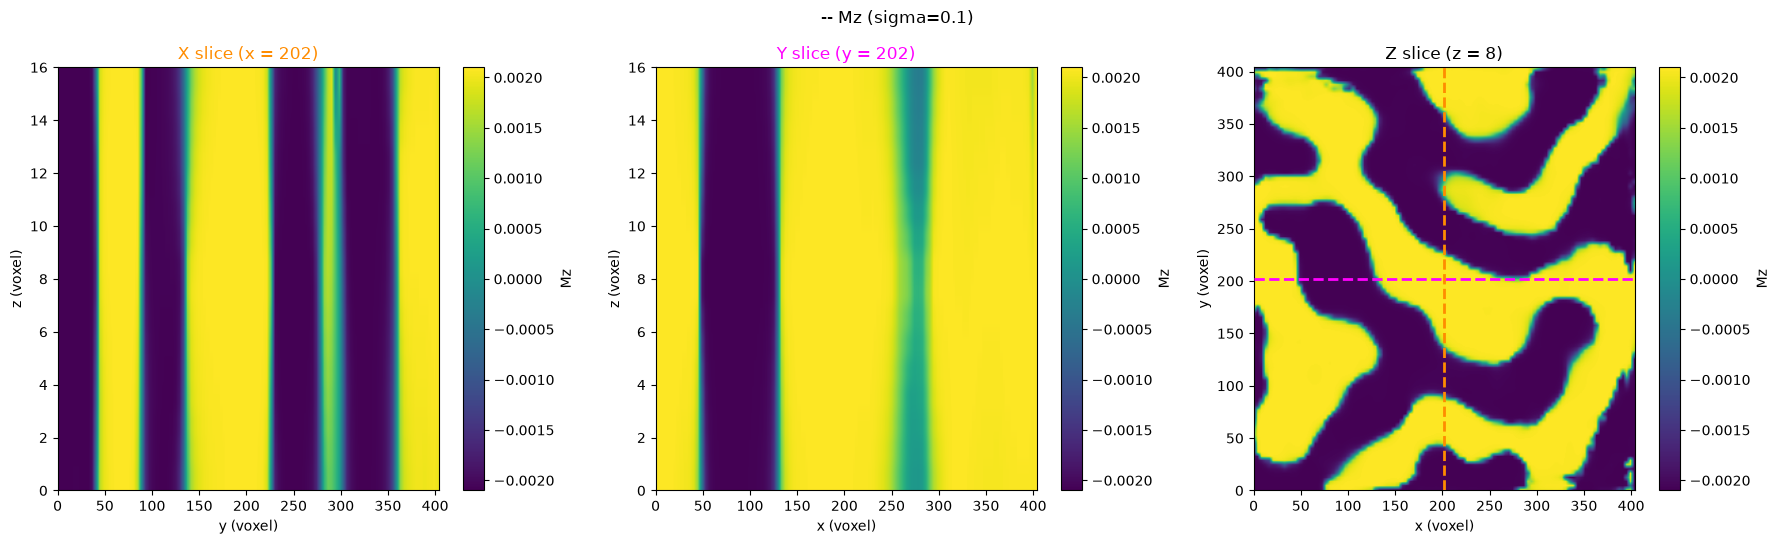

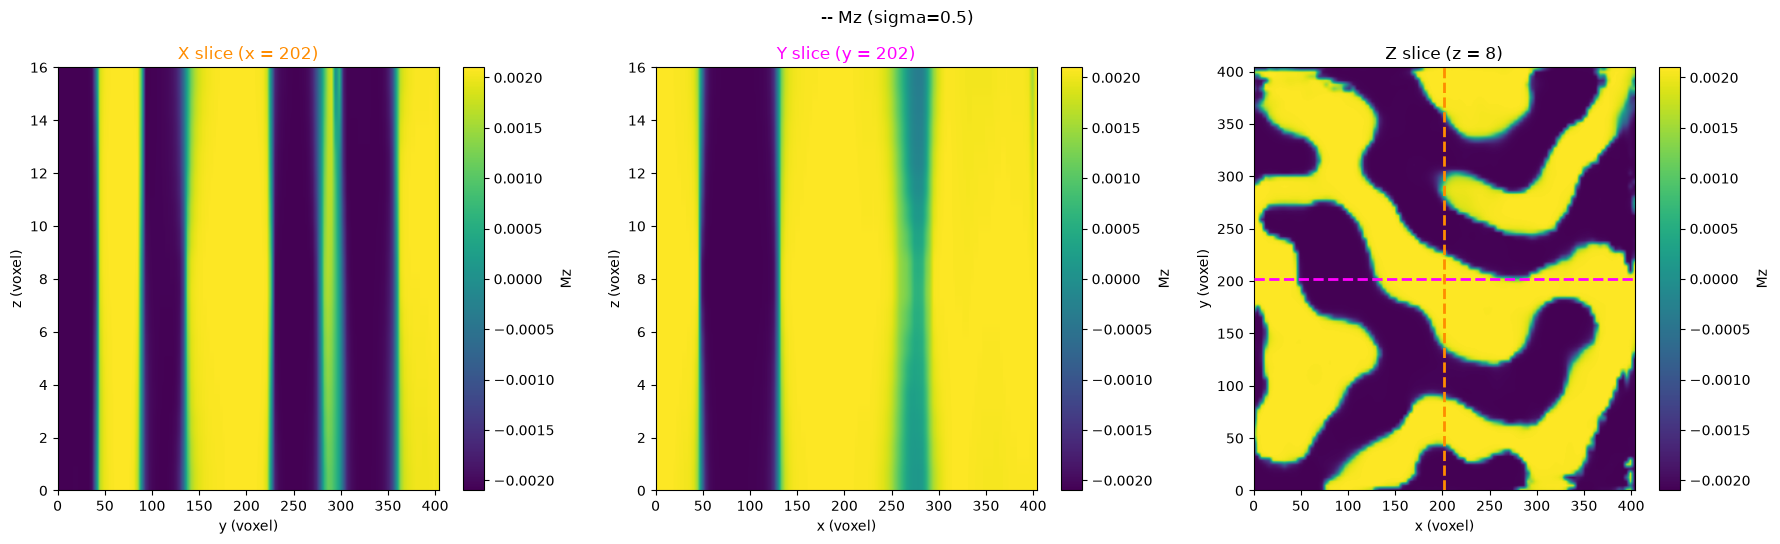

In [125]:
sigmas_to_test = [0.1, 0.5]

for s in sigmas_to_test:
    vis.apply_gaussian_blur_and_view(volume, field='Mz', sigma=s)


############## SELECT SIGMA TO SAVE ##############
sigma_save = 0.5
Mz_smooth = volume['smoothed']['Mz'][sigma_save]
##################################################

# Marching cubes isosurface extraction at Mz = 0

In [126]:
# %% [Cell 5: Interpolate Mx, My, Mz onto mesh vertices]
def sample_volume_at_points(volume, points_idx):
    """
    Trilinear interpolation of `volume` at fractional (z, y, x) index
    coordinates given in points_idx, shape (N, 3).
    """
    coords = points_idx.T  # map_coordinates wants shape (ndim, N)
    return map_coordinates(volume, coords, order=1, mode='nearest')

## Creat Iso surface

In [127]:
Mz = Mz_smooth       # shape (nz, ny, nx)
Mx = volume['Mx']
My = volume['My']

# spacing here scales the output vertex coordinates and normals into physical
# Level = 0 because this is where the domain wall center is!!! 
verts_phys, faces, normals_phys, values = marching_cubes(Mz, level=0.0, spacing=(dz, dy, dx), allow_degenerate=True) # Using allow_degenerate=False didn't visually change anything for 452

print(f"Extracted mesh: {verts_phys.shape[0]} vertices, {faces.shape[0]} triangles")

# Convert physical-space vertex coordinates back into fractional voxel-index
# coordinates (z_idx, y_idx, x_idx), since map_coordinates() needs index space.
verts_idx = verts_phys / np.array([dz, dy, dx])

#Correct normal sign convention]
###########  We want normals to consistently point from -Mz domain into +Mz domain.
# Check by sampling Mz slightly ahead of / behind each vertex along its normal.

eps_phys = 2.0  # step size in physical units; scale relative to your voxel size 
eps_idx = eps_phys / np.array([dz, dy, dx])

# normals_phys is in (z, y, x) order to match marching_cubes' internal axis order
step = normals_phys * eps_idx  # broadcast scale per-axis

pts_forward = verts_idx + step
pts_backward = verts_idx - step

Mz_forward = sample_volume_at_points(Mz, pts_forward)
Mz_backward = sample_volume_at_points(Mz, pts_backward)

# If moving along +normal decreases Mz, the normal is backwards -- flip it.
flip_mask = Mz_forward < Mz_backward
normals_phys[flip_mask] *= -1

print(f"Flipped {flip_mask.sum()} / {len(flip_mask)} normals to enforce -Mz -> +Mz convention")

# Reorder normals and vertex from (z, y, x) to (x, y, z) for consistency with M_v and PyVista
normals_xyz = normals_phys[:, ::-1]
verts_xyz = verts_phys[:, ::-1]  


Extracted mesh: 74386 vertices, 139572 triangles
Flipped 74386 / 74386 normals to enforce -Mz -> +Mz convention


## Sample Volume at points to create useful mesh

In [128]:
Mx_v = sample_volume_at_points(Mx, verts_idx)
My_v = sample_volume_at_points(My, verts_idx)
Mz_v = sample_volume_at_points(Mz, verts_idx)  # sample raw (unsmoothed) Mz for the actual physical vector
M_v = np.stack([Mx_v, My_v, Mz_v], axis=1)      # shape (N, 3), order (x, y, z) per vertex

## Calculate dw angles

In [129]:
def compute_chirality_angle(M_v, normals_xyz, up_axis=np.array([0.0, 0.0, 1.0])):
    """
    Compute a signed angle capturing both wall type (Neel vs Bloch) and
    chirality (rotation sense), for each mesh vertex.

    Parameters
    ----------
    M_v : (N, 3) array
        Magnetization vectors at each mesh vertex (x, y, z order).
    normals_xyz : (N, 3) array
        Wall normal vectors at each mesh vertex (x, y, z order), already
        sign-corrected to point from -Mz into +Mz domain.
    up_axis : (3,) array
        Reference axis used to define tangential direction, defaults to
        the film's easy axis (z), appropriate for PMA films.

    Returns
    -------
    psi_chiral : (N,) array, degrees, range (-180, 180]
        0 deg   -> Neel, pointing along +n_hat
        180 deg -> Neel, pointing along -n_hat (opposite polarity)
        +90 deg -> Bloch, curling in +t_hat direction
        -90 deg -> Bloch, curling in -t_hat direction
    t_hat : (N, 3) array
        The tangential unit vector used at each vertex, in case you want
        to visualize it directly (e.g. as arrows alongside the normals).
    degenerate_mask : (N,) bool array
        True where n_hat was parallel to up_axis, making t_hat undefined
        (chirality is meaningless there; check how many/where this occurs).
    """
    up = np.broadcast_to(up_axis, normals_xyz.shape)
    t_vec = np.cross(up, normals_xyz)  # automatically perpendicular to normals_xyz
    t_norm = np.linalg.norm(t_vec, axis=1)

    degenerate_mask = t_norm < 1e-8
    if np.any(degenerate_mask):
        print(f"Warning: {degenerate_mask.sum()} / {len(degenerate_mask)} vertices "
              f"have normals parallel to up_axis; chirality undefined there.")
        t_norm = np.where(degenerate_mask, 1.0, t_norm)  # avoid divide-by-zero

    t_hat = t_vec / t_norm[:, None]

    M_n = np.einsum('ij,ij->i', M_v, normals_xyz)   # signed, along normal
    M_t_signed = np.einsum('ij,ij->i', M_v, t_hat)   # signed, along tangent

    psi_chiral = np.degrees(np.arctan2(M_t_signed, M_n))

    return psi_chiral, t_hat, degenerate_mask

In [130]:
# Compute Bloch/Néel character angle at each vertex]
M_n = np.einsum('ij,ij->i', M_v, normals_xyz)          # M component along normal
#M_n = np.linalg.norm(M_v, axis=1)
M_t_vec = M_v - M_n[:, None] * normals_xyz
M_t_mag = np.linalg.norm(M_t_vec, axis=1)
psi_unsigned = np.degrees(np.arctan2(M_t_mag, M_n))             # 0/180 = Néel-like, +-90 = Bloch-like
psi_chiral, t_hat, degenerate_mask = compute_chirality_angle(M_v, normals_xyz)

In [131]:
div_x = sample_volume_at_points(divergence['div_x'], verts_idx)
div_y = sample_volume_at_points(divergence['div_y'], verts_idx)
div_z = sample_volume_at_points(divergence['div_z'], verts_idx)  # sample raw (unsmoothed) Mz for the actual physical vector
div_M= sample_volume_at_points(divergence['div_M'], verts_idx) 
source = sample_volume_at_points(divergence['source_mask'], verts_idx) 
sink = sample_volume_at_points(divergence['sink_mask'], verts_idx) 


## save iso cut in df

In [132]:
def build_wall_dataframe(verts_xyz, normals_xyz, t_hat, M_v,
                          psi_unsigned, psi_chiral, M_normal, degenerate_mask,
                          spacing=(8.0, 8.0, 8.0)):
    """
    Consolidate all per-vertex wall quantities into a single tidy DataFrame,
    one row per mesh vertex. spacing = (dz, dy, dx) in physical units, used
    to also store voxel-index coordinates for binning/slicing by layer.
    """
    dz, dy, dx = spacing
    df = pd.DataFrame({
        'x': verts_xyz[:, 0], 'y': verts_xyz[:, 1], 'z': verts_xyz[:, 2],
        'ix': verts_xyz[:, 0] / dx, 'iy': verts_xyz[:, 1] / dy, 'iz': verts_xyz[:, 2] / dz,
        'nx': normals_xyz[:, 0], 'ny': normals_xyz[:, 1], 'nz': normals_xyz[:, 2],
        'tx': t_hat[:, 0], 'ty': t_hat[:, 1], 'tz': t_hat[:, 2],
        'Mx': M_v[:, 0], 'My': M_v[:, 1], 'Mz': M_v[:, 2],
        'M_normal': M_n,
        'psi_unsigned': psi_unsigned,
        'psi_chiral': psi_chiral,
        'degenerate': degenerate_mask,
    })
    df['vertex_id'] = df.index
    return df

wall_df = build_wall_dataframe(verts_xyz, normals_xyz, t_hat, M_v,
                                psi_unsigned, psi_chiral, M_n, degenerate_mask)

In [133]:
wall_df['curl_magnitude'] = sample_volume_at_points(curl['curl_magnitude'], verts_idx)
wall_df['PMA'] = sample_volume_at_points(energies['PMA'], verts_idx)
wall_df['Exchange'] = sample_volume_at_points(energies['Divergence'], verts_idx)
wall_df['iDMI'] = sample_volume_at_points(energies['iDMI'], verts_idx)
wall_df['Nsk'] = sample_volume_at_points(topology['q_density'], verts_idx)

wall_df['Mx'] = Mx_v
wall_df['My'] = My_v

wall_df['div_M'] = div_M
wall_df['source'] = source
wall_df['sink'] = sink


# Plot Iso-Surface

In [134]:
def add_volume_slice_pv(plotter, sample, field='Mz', axis='z', index=None,
                         sigma=None, spacing=(2.0, 2.0, 2.0),
                         cmap='viridis', opacity=0.7, vmin=None, vmax=None,
                         show_scalar_bar=False):
    """
    Add a single axis-aligned voxel slice of `field` to a PyVista plotter,
    using the same index convention as plot_three_slice (axis + voxel index).

    axis : 'x', 'y', or 'z' -- which axis to slice along
    index : voxel index along that axis (defaults to center)
    sigma : if not None, use the cached smoothed volume at that sigma
            (sample['smoothed'][key][sigma], as populated by plot_three_slice)
    spacing : (dz, dy, dx) physical voxel size, e.g. (8.0, 8.0, 8.0) for your data
    """
    field_aliases = {'mag': 'magnitude', 'magnitude': 'magnitude',
                      'mx': 'Mx', 'my': 'My', 'mz': 'Mz'}
    key = field_aliases.get(field.lower())
    data = sample[key] if sigma is None else sample['smoothed'][key][sigma]

    nz, ny, nx = sample['shape']
    dz, dy, dx = spacing

    if vmin is None:
        vmin = np.nanmin(sample[key])
    if vmax is None:
        vmax = np.nanmax(sample[key])

    # Build the full 3D grid with correctly-ordered cell data
    grid = pv.ImageData()
    grid.dimensions = np.array((nx, ny, nz)) + 1  # point dims = cell dims + 1
    grid.spacing = (dx, dy, dz)
    grid.origin = (0, 0, 0)
    grid.cell_data[key] = data.flatten(order='C')  # corrected order

    # Default index = center of chosen axis, same as plot_three_slice
    default_index = {'x': nx // 2, 'y': ny // 2, 'z': nz // 2}
    if index is None:
        index = default_index[axis]

    normal_map = {'x': (1, 0, 0), 'y': (0, 1, 0), 'z': (0, 0, 1)}
    spacing_map = {'x': dx, 'y': dy, 'z': dz}
    axis_pos_idx = {'x': 0, 'y': 1, 'z': 2}

    # Place the cutting plane at the *center* of the chosen voxel layer,
    # so the cut passes through the middle of those cells and returns their
    # exact values rather than something interpolated between layers.
    origin = [0.0, 0.0, 0.0]
    origin[axis_pos_idx[axis]] = (index + 0.5) * spacing_map[axis]

    sliced = grid.slice(normal=normal_map[axis], origin=tuple(origin))

    plotter.add_mesh(sliced, scalars=key, cmap=cmap, opacity=opacity,
                      clim=[vmin, vmax], show_scalar_bar=show_scalar_bar)
    return sliced

def plot_map(sample, verts_xyz, faces, plot_dict, sargs, show_grid = True, field = 'Mz', axis = 'z'):
    """
    Visualize the signed chirality/wall-type angle on the domain wall mesh.

    Parameters
    ----------
    verts_xyz, faces : mesh geometry, as produced by marching_cubes
    psi_chiral : (N,) array, degrees, from compute_chirality_angle
    cmap : colormap; 'twilight' or 'hsv' are good choices since they're
        cyclic and represent the wraparound at +-180 deg without a
        visually misleading hard color jump
    show_normals, show_tangents : optionally overlay arrows for n_hat
        and/or t_hat (pass normals_xyz / t_hat if enabling these)
    """

    axis_view = axis
    field_view = field

    cmap = plot_dict['color_map']
    min = plot_dict['bounds'][0]
    max = plot_dict['bounds'][1]


    faces_pv = np.hstack([np.full((faces.shape[0], 1), 3), faces]).astype(np.int64)
    mesh = pv.PolyData(verts_xyz, faces_pv)
    mesh['key_to_map'] = plot_dict['view']

    plotter = pv.Plotter()
    plotter.add_mesh(
        mesh, scalars='key_to_map', cmap=cmap, clim=[min, max], scalar_bar_args=sargs)

    if show_grid: 
        M = sample[field]
        grid = pv.ImageData()
        grid.dimensions = np.array(Mz.shape[::-1]) + 1   # (Mz = samples[sample_name]['cropped']['Mz'] )
        # print(np.array(Mz.shape[::-1]) +1 )
        grid.spacing = (2.0, 2.0, 2.0) #################### HARD CODED FOR 8nm VOXEL SIZE 
        grid.origin = (0, 0, 0)
        grid.cell_data['Mz'] = Mz.flatten(order='C')  # note: flatten order matters, check orientation
        add_volume_slice_pv(plotter, sample, field=field_view, axis=axis_view, index=0, opacity=0.2)  # defaults to center


    plotter.view_isometric()      # view_isometric   view_xy
    plotter.camera.zoom(plot_dict['zoom'])
    plotter.camera.azimuth += 270
    plotter.add_axes()
    plotter.show()
    
    return mesh

In [135]:
# mesh['Normals'] = normals_xyz
# mesh['Mn'] = M_n
# mesh['psi_deg'] = psi_unsigned
# mesh['Mz_at_vertex'] = Mz_v
# mesh['Mx'] = Mx_v
# mesh['My'] = My_v

## Computed Angles

C:\Users\emmab\AppData\Local\Temp\ipykernel_2824\1547255203.py:102: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


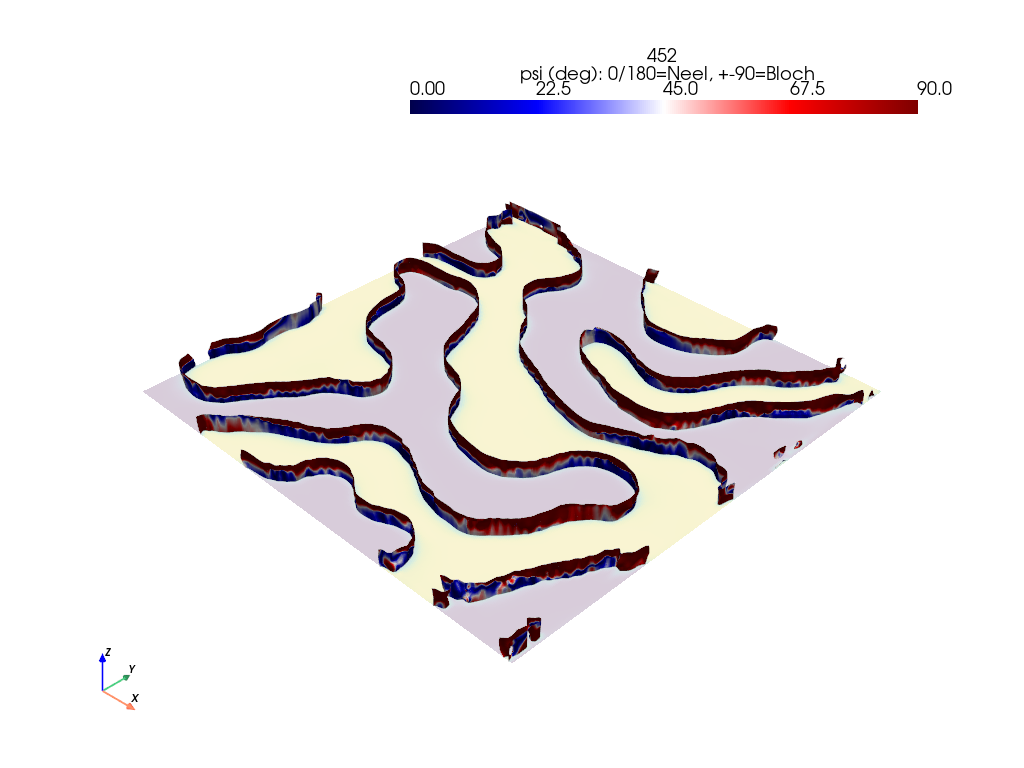

PolyData (0x247a2bb7d60)
  N Cells:    139572
  N Points:   74386
  N Strips:   0
  X Bounds:   0.000e+00, 8.060e+02
  Y Bounds:   0.000e+00, 8.060e+02
  Z Bounds:   0.000e+00, 3.000e+01
  N Arrays:   1

In [136]:
# # # # Wall surface colored by psi character
sargs = dict(
    position_x=0.4,  # Move towards the right edge
    position_y=0.85,   # Move near the bottom
    height=0.05,       # Make it take up 50% of window height
    width=0.5,        # Width of the bar
    vertical=False,    # Orientation
    title = f'{sample_name} \n psi (deg): 0/180=Neel, +-90=Bloch'
)

psi_plot_dict = dict(
    view= psi_unsigned, 
    bounds = [0, 90],
    color_map = 'seismic', 
    zoom = 1
)

plot_map(volume, verts_xyz, faces, psi_plot_dict, sargs, show_grid = True, field = 'Mz', axis = 'z')

C:\Users\emmab\AppData\Local\Temp\ipykernel_2824\1547255203.py:102: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


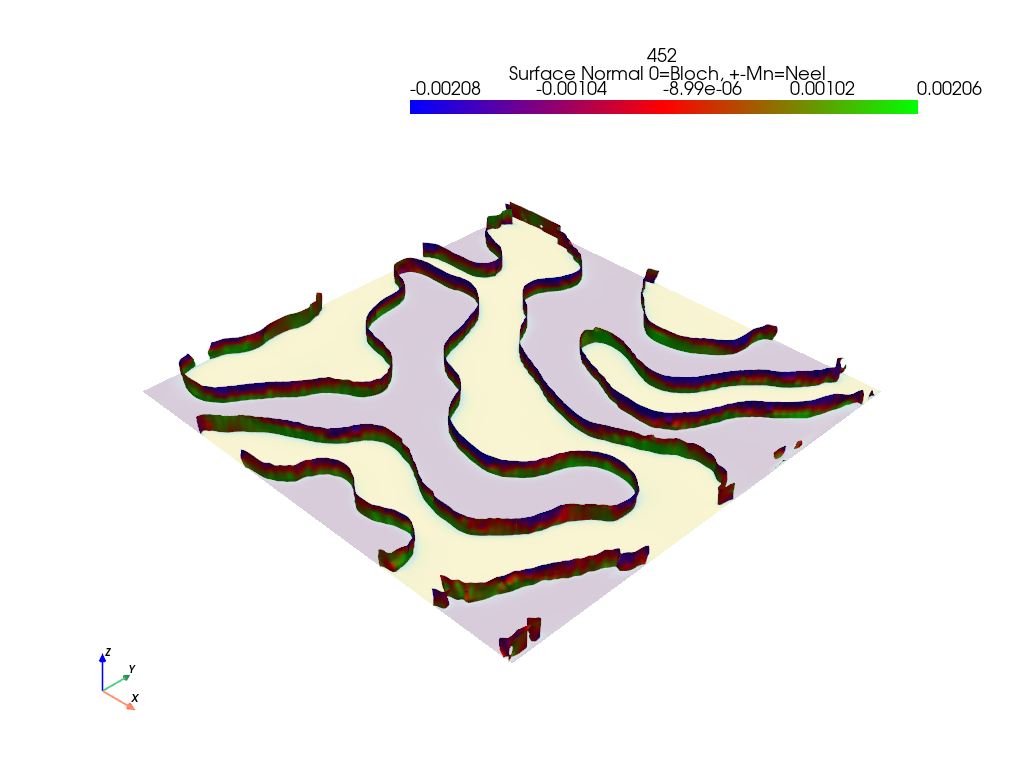

PolyData (0x248c6094be0)
  N Cells:    139572
  N Points:   74386
  N Strips:   0
  X Bounds:   0.000e+00, 8.060e+02
  Y Bounds:   0.000e+00, 8.060e+02
  Z Bounds:   0.000e+00, 3.000e+01
  N Arrays:   1

In [137]:
sargs = dict(
    position_x=0.4,  # Move towards the right edge
    position_y=0.85,   # Move near the bottom
    height=0.05,       # Make it take up 50% of window height
    width=0.5,        # Width of the bar
    vertical=False,    # Orientation
    title = f'{sample_name} \n Surface Normal 0=Bloch, +-Mn=Neel'
)

psi_plot_dict = dict(
    view= M_n, 
    bounds = [np.min(My_v), np.max(My_v)],
    color_map = 'brg', 
    zoom = 1
)

plot_map(volume, verts_xyz, faces, psi_plot_dict, sargs, show_grid = True, field = 'Mz', axis = 'z')



C:\Users\emmab\AppData\Local\Temp\ipykernel_2824\1547255203.py:102: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


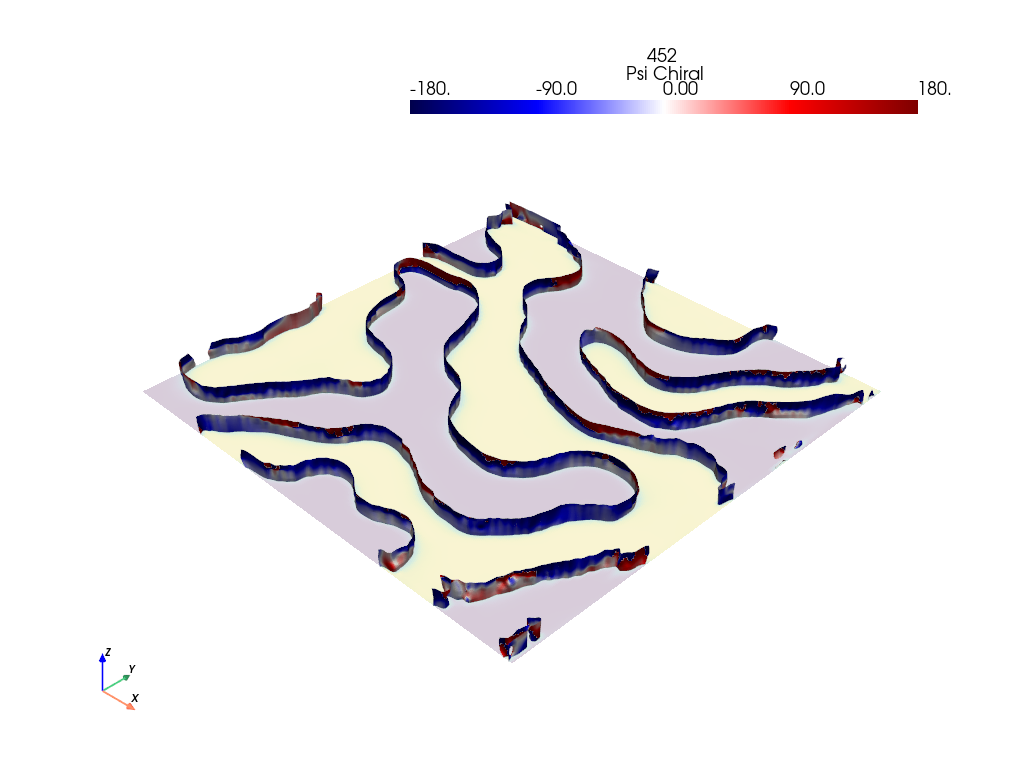

PolyData (0x248c6041f60)
  N Cells:    139572
  N Points:   74386
  N Strips:   0
  X Bounds:   0.000e+00, 8.060e+02
  Y Bounds:   0.000e+00, 8.060e+02
  Z Bounds:   0.000e+00, 3.000e+01
  N Arrays:   1

In [138]:
sargs = dict(
    position_x=0.4,  # Move towards the right edge
    position_y=0.85,   # Move near the bottom
    height=0.05,       # Make it take up 50% of window height
    width=0.5,        # Width of the bar
    vertical=False,    # Orientation
    title = f'{sample_name} \n Psi Chiral '
)

psi_plot_dict = dict(
    view= psi_chiral, 
    bounds = [-180, 180],
    color_map = 'seismic', 
    zoom = 1
)

plot_map(volume, verts_xyz, faces, psi_plot_dict, sargs, show_grid = True, field = 'Mz', axis = 'z')


## Computed Vectors and Energies

C:\Users\emmab\AppData\Local\Temp\ipykernel_2824\1547255203.py:102: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


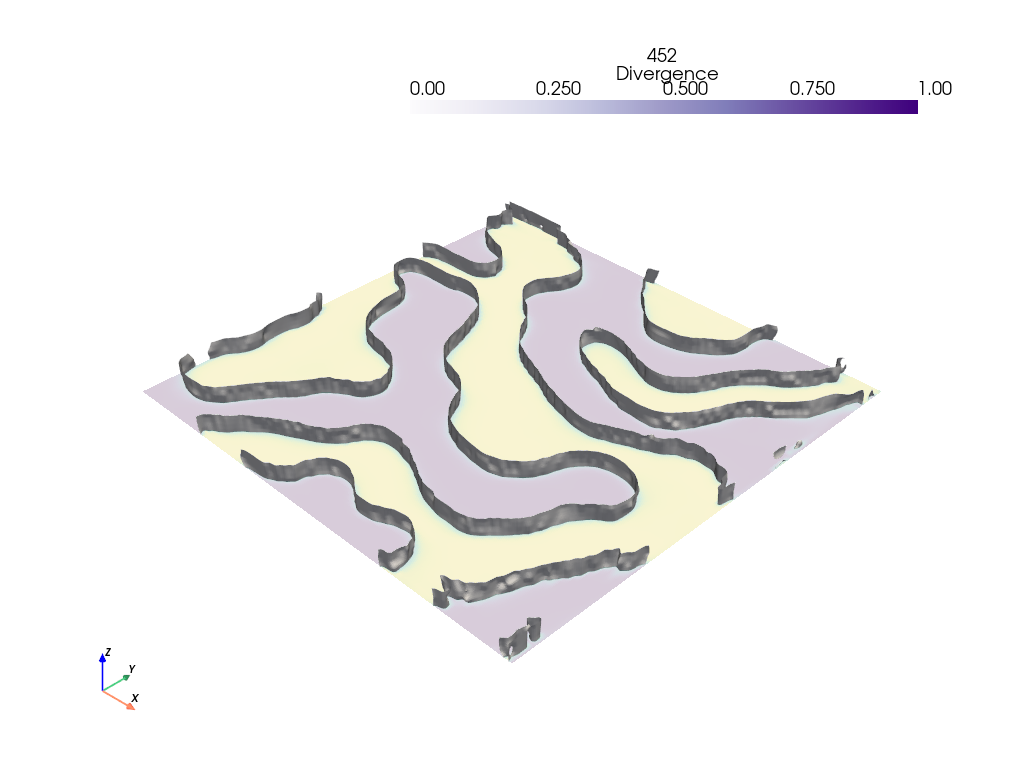

PolyData (0x248c61076a0)
  N Cells:    139572
  N Points:   74386
  N Strips:   0
  X Bounds:   0.000e+00, 8.060e+02
  Y Bounds:   0.000e+00, 8.060e+02
  Z Bounds:   0.000e+00, 3.000e+01
  N Arrays:   1

In [139]:
sargs = dict(
    position_x=0.4,  # Move towards the right edge
    position_y=0.85,   # Move near the bottom
    height=0.05,       # Make it take up 50% of window height
    width=0.5,        # Width of the bar
    vertical=False,    # Orientation
    title = f'{sample_name} \n Divergence'
)

psi_plot_dict = dict(
    view= wall_df['Exchange'].values *10000000, 
    bounds = [0, 1],
    color_map = 'Purples', 
    zoom = 1
)

plot_map(volume, verts_xyz, faces, psi_plot_dict, sargs, show_grid = True, field = 'Mz', axis = 'z')

C:\Users\emmab\AppData\Local\Temp\ipykernel_2824\1547255203.py:102: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


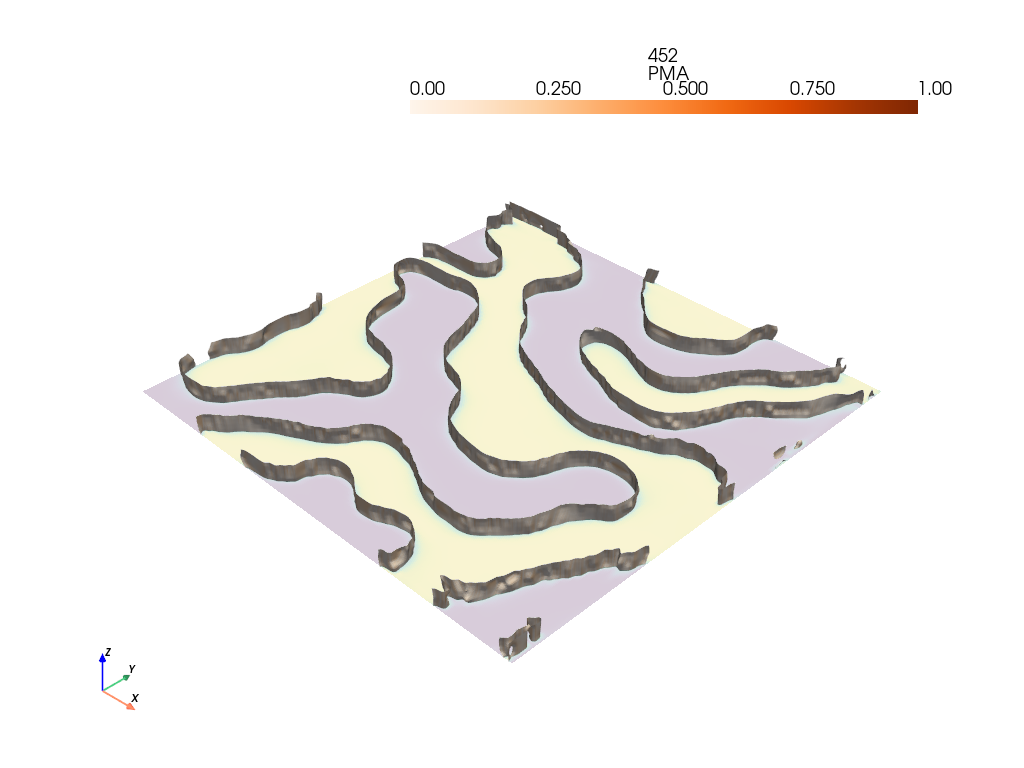

PolyData (0x248c6043f40)
  N Cells:    139572
  N Points:   74386
  N Strips:   0
  X Bounds:   0.000e+00, 8.060e+02
  Y Bounds:   0.000e+00, 8.060e+02
  Z Bounds:   0.000e+00, 3.000e+01
  N Arrays:   1

In [140]:
sargs = dict(
    position_x=0.4,  # Move towards the right edge
    position_y=0.85,   # Move near the bottom
    height=0.05,       # Make it take up 50% of window height
    width=0.5,        # Width of the bar
    vertical=False,    # Orientation
    title = f'{sample_name} \n PMA'
)

psi_plot_dict = dict(
    view= wall_df['PMA'].values *1000000 , 
    bounds = [0, 1],
    color_map = 'Oranges', 
    zoom = 1
)

plot_map(volume, verts_xyz, faces, psi_plot_dict, sargs, show_grid = True, field = 'Mz', axis = 'z')

C:\Users\emmab\AppData\Local\Temp\ipykernel_2824\1547255203.py:102: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


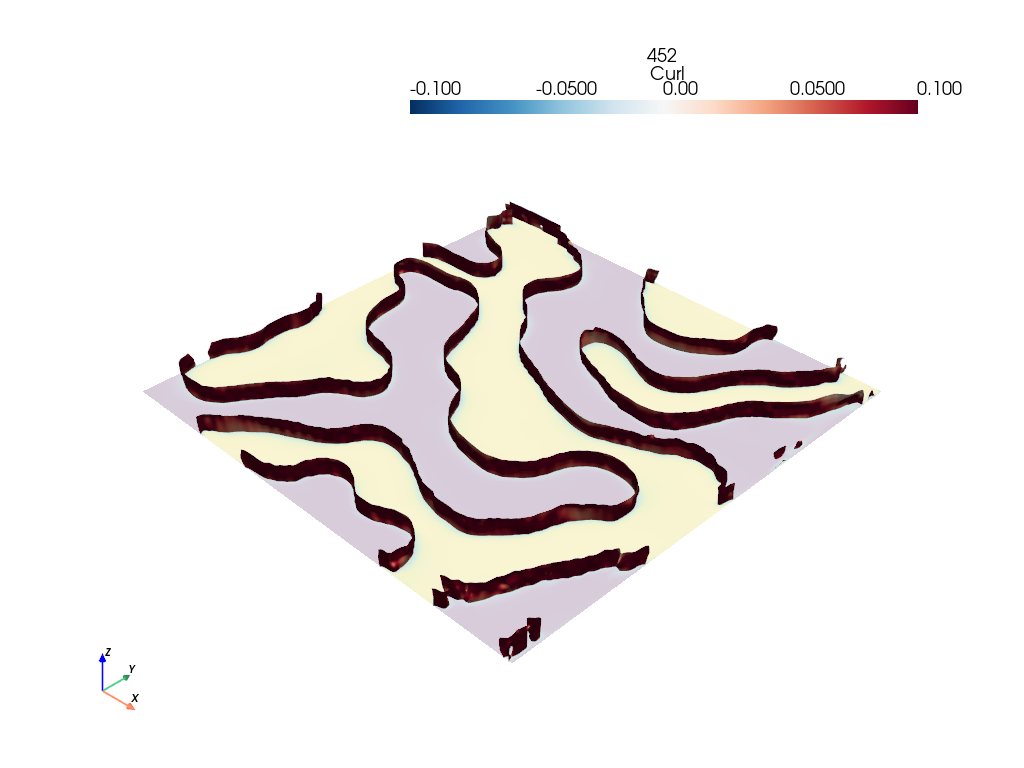

PolyData (0x248c6041fc0)
  N Cells:    139572
  N Points:   74386
  N Strips:   0
  X Bounds:   0.000e+00, 8.060e+02
  Y Bounds:   0.000e+00, 8.060e+02
  Z Bounds:   0.000e+00, 3.000e+01
  N Arrays:   1

In [141]:
sargs = dict(
    position_x=0.4,  # Move towards the right edge
    position_y=0.85,   # Move near the bottom
    height=0.05,       # Make it take up 50% of window height
    width=0.5,        # Width of the bar
    vertical=False,    # Orientation
    title = f'{sample_name} \n Curl'
)

psi_plot_dict = dict(
    view= wall_df['curl_magnitude'].values *1000 , 
    bounds = [-0.1, 0.1],
    color_map = 'RdBu_r', 
    zoom = 1
)

plot_map(volume, verts_xyz, faces, psi_plot_dict, sargs, show_grid = True, field = 'Mz', axis = 'z')

C:\Users\emmab\AppData\Local\Temp\ipykernel_2824\1547255203.py:102: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


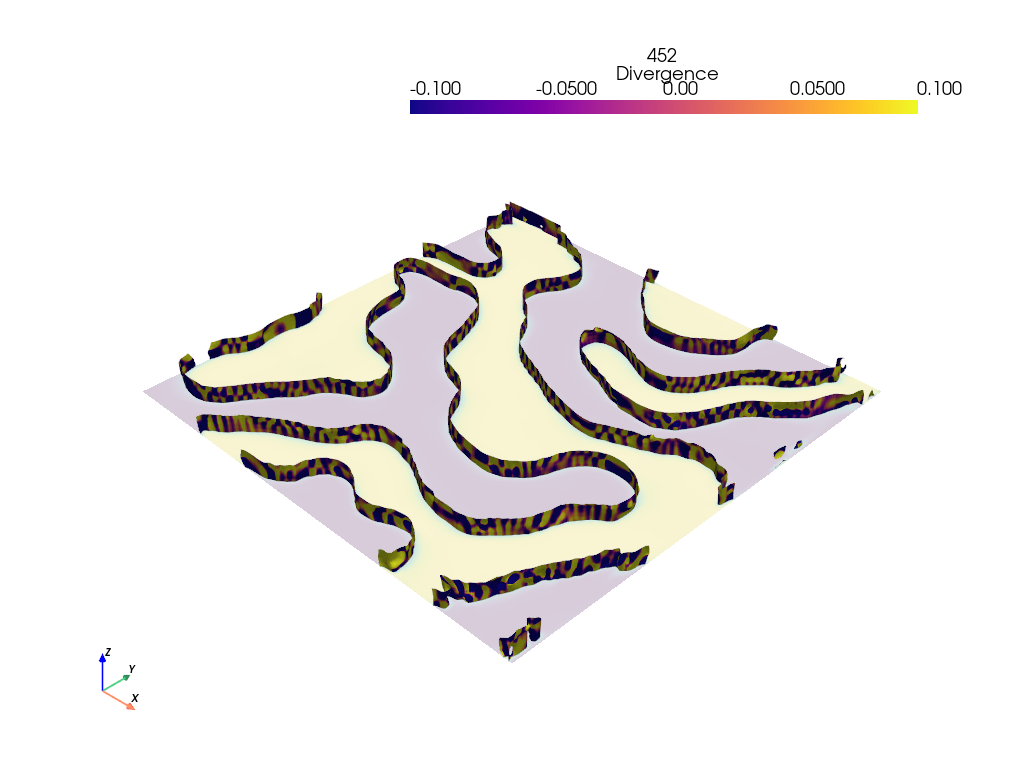

PolyData (0x248c6043040)
  N Cells:    139572
  N Points:   74386
  N Strips:   0
  X Bounds:   0.000e+00, 8.060e+02
  Y Bounds:   0.000e+00, 8.060e+02
  Z Bounds:   0.000e+00, 3.000e+01
  N Arrays:   1

In [142]:
sargs = dict(
    position_x=0.4,  # Move towards the right edge
    position_y=0.85,   # Move near the bottom
    height=0.05,       # Make it take up 50% of window height
    width=0.5,        # Width of the bar
    vertical=False,    # Orientation
    title = f'{sample_name} \n Divergence'
)

psi_plot_dict = dict(
    view= wall_df['div_M'].values *10000 , 
    bounds = [-0.1, 0.1],
    color_map = 'plasma', 
    zoom = 1
)

plot_map(volume, verts_xyz, faces, psi_plot_dict, sargs, show_grid = True, field = 'Mz', axis = 'z')

C:\Users\emmab\AppData\Local\Temp\ipykernel_2824\1547255203.py:102: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


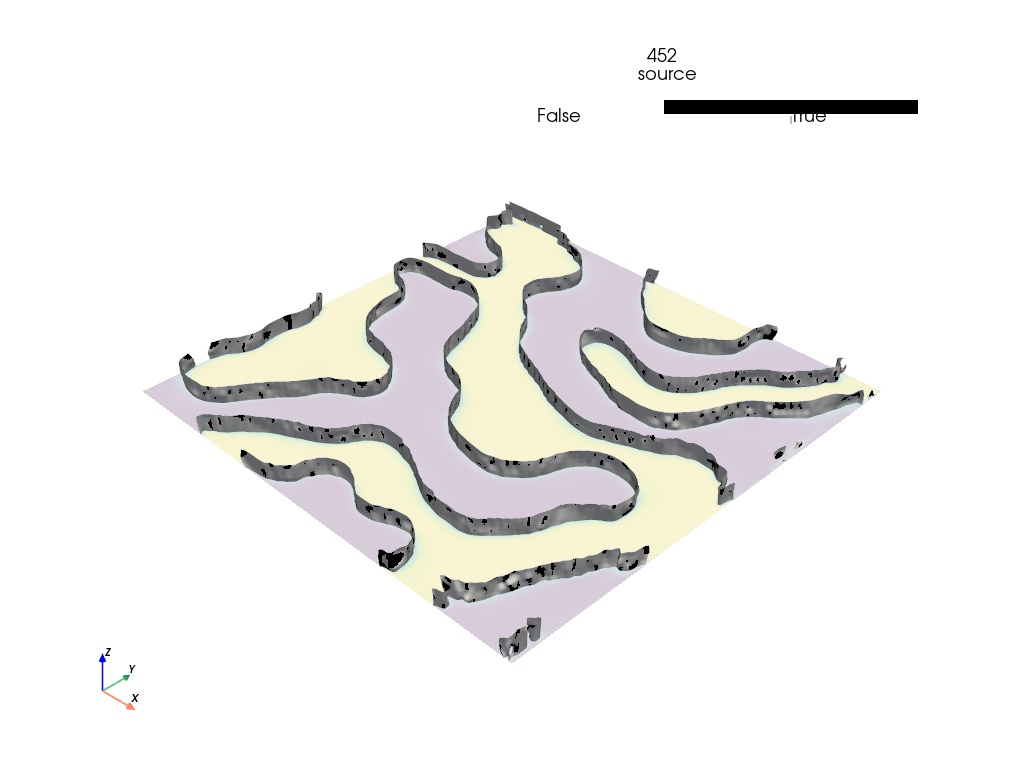

PolyData (0x248c6040340)
  N Cells:    139572
  N Points:   74386
  N Strips:   0
  X Bounds:   0.000e+00, 8.060e+02
  Y Bounds:   0.000e+00, 8.060e+02
  Z Bounds:   0.000e+00, 3.000e+01
  N Arrays:   1

In [143]:
sargs = dict(
    position_x=0.4,  # Move towards the right edge
    position_y=0.85,   # Move near the bottom
    height=0.05,       # Make it take up 50% of window height
    width=0.5,        # Width of the bar
    vertical=False,    # Orientation
    title = f'{sample_name} \n source'
)

psi_plot_dict = dict(
    view= wall_df['source'].values, 
    bounds = [-1, 1],
    color_map = 'Greys', 
    zoom = 1
)

plot_map(volume, verts_xyz, faces, psi_plot_dict, sargs, show_grid = True, field = 'Mz', axis = 'z')

C:\Users\emmab\AppData\Local\Temp\ipykernel_2824\1547255203.py:102: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


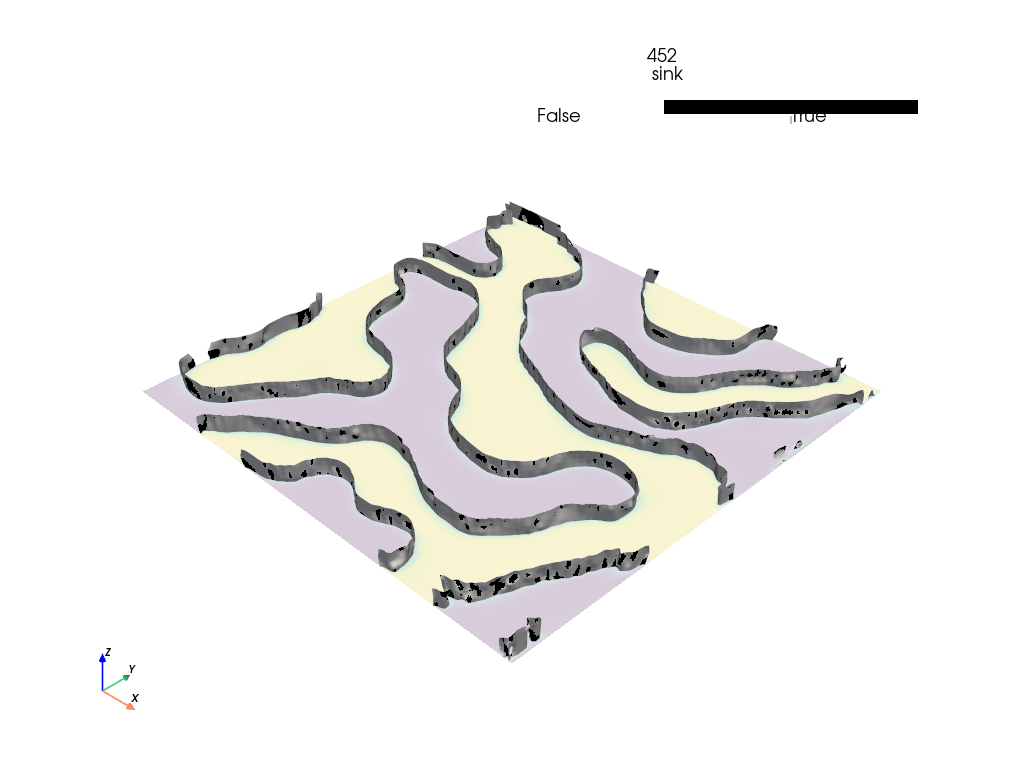

PolyData (0x248c6059000)
  N Cells:    139572
  N Points:   74386
  N Strips:   0
  X Bounds:   0.000e+00, 8.060e+02
  Y Bounds:   0.000e+00, 8.060e+02
  Z Bounds:   0.000e+00, 3.000e+01
  N Arrays:   1

In [144]:
sargs = dict(
    position_x=0.4,  # Move towards the right edge
    position_y=0.85,   # Move near the bottom
    height=0.05,       # Make it take up 50% of window height
    width=0.5,        # Width of the bar
    vertical=False,    # Orientation
    title = f'{sample_name} \n sink'
)

psi_plot_dict = dict(
    view= wall_df['sink'].values, 
    bounds = [-1, 1],
    color_map = 'Greys', 
    zoom = 1
)

plot_map(volume, verts_xyz, faces, psi_plot_dict, sargs, show_grid = True, field = 'Mz', axis = 'z')

C:\Users\emmab\AppData\Local\Temp\ipykernel_2824\1547255203.py:102: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


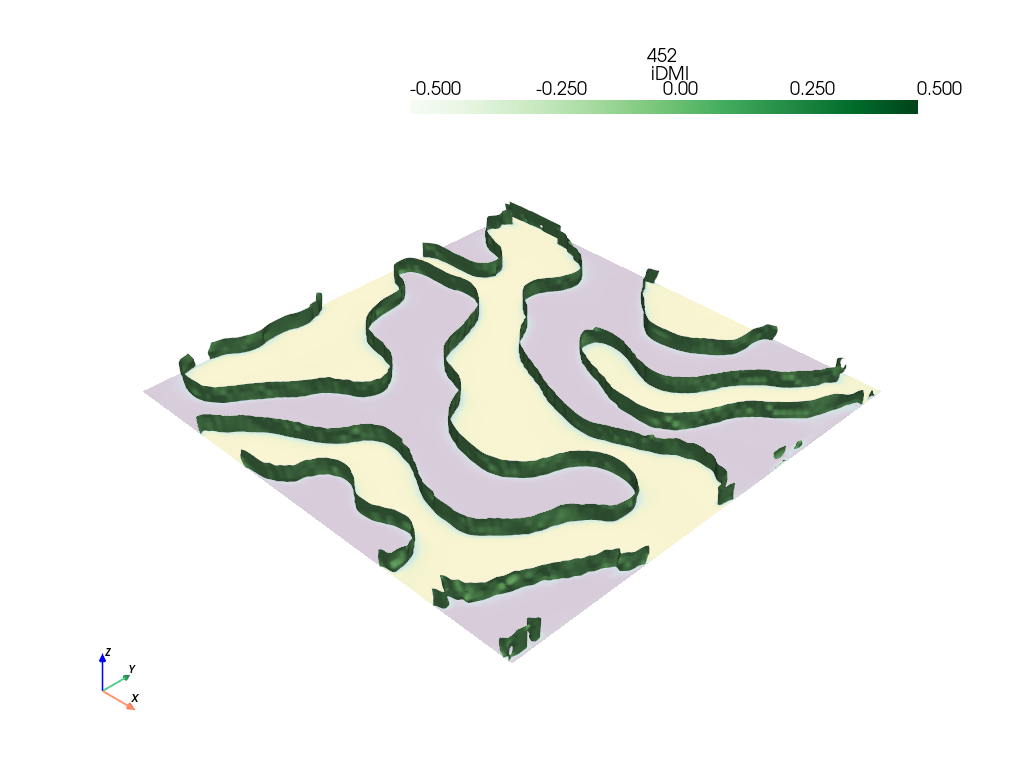

PolyData (0x247d37b7e20)
  N Cells:    139572
  N Points:   74386
  N Strips:   0
  X Bounds:   0.000e+00, 8.060e+02
  Y Bounds:   0.000e+00, 8.060e+02
  Z Bounds:   0.000e+00, 3.000e+01
  N Arrays:   1

In [145]:
sargs = dict(
    position_x=0.4,  # Move towards the right edge
    position_y=0.85,   # Move near the bottom
    height=0.05,       # Make it take up 50% of window height
    width=0.5,        # Width of the bar
    vertical=False,    # Orientation
    title = f'{sample_name} \n  iDMI'
)

psi_plot_dict = dict(
    view= wall_df['iDMI'].values * 10, 
    bounds = [-0.5, 0.5],
    color_map = 'Greens', 
    zoom = 1
)

plot_map(volume, verts_xyz, faces, psi_plot_dict, sargs, show_grid = True, field = 'Mz', axis = 'z')

C:\Users\emmab\AppData\Local\Temp\ipykernel_2824\1547255203.py:102: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


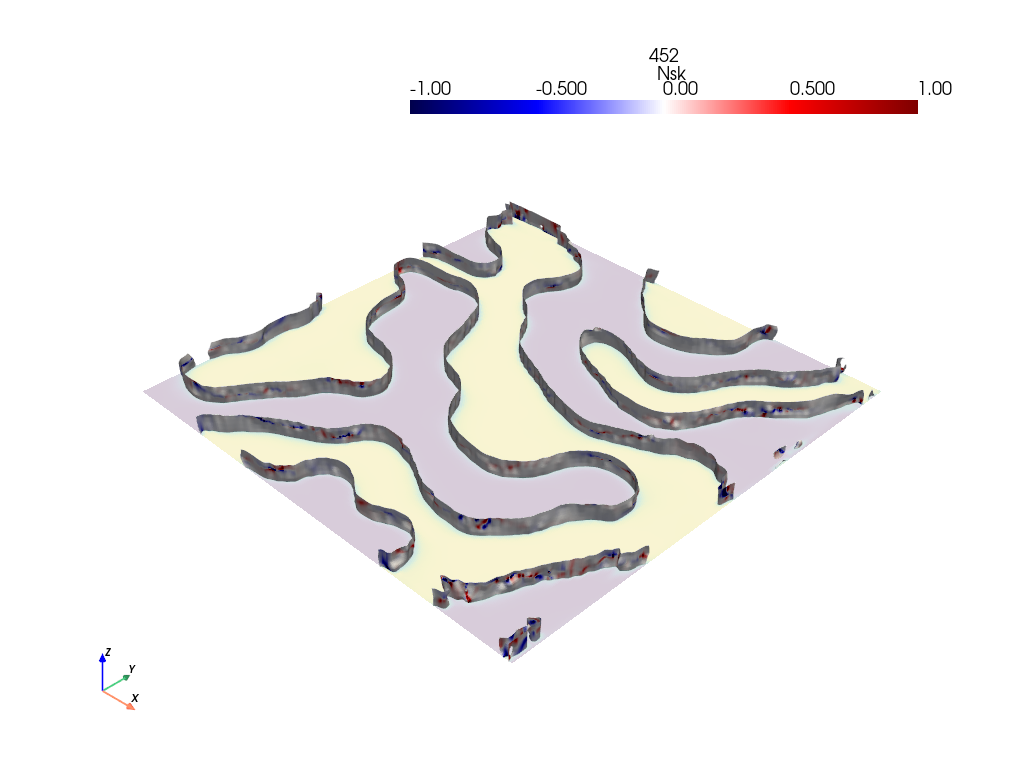

PolyData (0x248c605ac80)
  N Cells:    139572
  N Points:   74386
  N Strips:   0
  X Bounds:   0.000e+00, 8.060e+02
  Y Bounds:   0.000e+00, 8.060e+02
  Z Bounds:   0.000e+00, 3.000e+01
  N Arrays:   1

In [146]:
sargs = dict(
    position_x=0.4,  # Move towards the right edge
    position_y=0.85,   # Move near the bottom
    height=0.05,       # Make it take up 50% of window height
    width=0.5,        # Width of the bar
    vertical=False,    # Orientation
    title = f'{sample_name} \n  Nsk'
)

psi_plot_dict = dict(
    view= wall_df['Nsk'].values*1000, 
    bounds = [-1, 1],
    color_map = 'seismic', 
    zoom = 1
)

plot_map(volume, verts_xyz, faces, psi_plot_dict, sargs, show_grid = True, field = 'Mz', axis = 'z')

In [147]:
stop

NameError: name 'stop' is not defined

# Analyze Iso-Surfaces


In [ ]:
def plot_angle_vs_z(wall_df, bounds, angle_col='psi_chiral',  bloch_axis = None , neel_axis = None , title = None):
    df = wall_df.copy()
    z_lo, z_hi = bounds
    z_min = z_lo - z_lo
    z_max = z_hi - z_lo
   

    df['z_layer'] = df['iz'].round().astype(int)
    # print(df['iz'].min(), df['iz'].max())
    # print(df['z_layer'].value_counts().sort_index() if 'z_layer' in df else 'not yet computed')

    # Restrict to the physical film thickness, excluding any background/
    # padding layers from the tomography reconstruction.
    n_before = len(df)
    df = df[(df['z_layer'] >= z_min) & (df['z_layer'] <= z_max)]
    print(f"{len(df)} / {n_before} vertices fall within layers {z_min}-{z_max}")


    grouped = df.groupby('z_layer')[angle_col].agg(['mean', 'std', 'count'])

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.errorbar(grouped.index, grouped['mean'], yerr=grouped['std'],
                fmt='o-', capsize=3)

    if bloch_axis== None:
        print('no axis')
    else:
        print(bloch_axis)
        for deg in bloch_axis: 
            ax.axhline(deg, color = 'magenta', label = 'Bloch Wall')
        for deg in neel_axis:
            ax.axhline(deg, color = 'cyan', label = 'Neel Wall')
    ax.set_xlabel('z voxel layer')
    ax.set_xticks(range(z_min, z_max))
    ax.set_ylabel(f'{angle_col} (deg)')
    ax.set_title(f'{angle_col} vs. thickness position \n {title}')
    # plt.legend()
    plt.tight_layout()
    plt.show()
    return grouped




74386 / 74386 vertices fall within layers 0-4
[45]


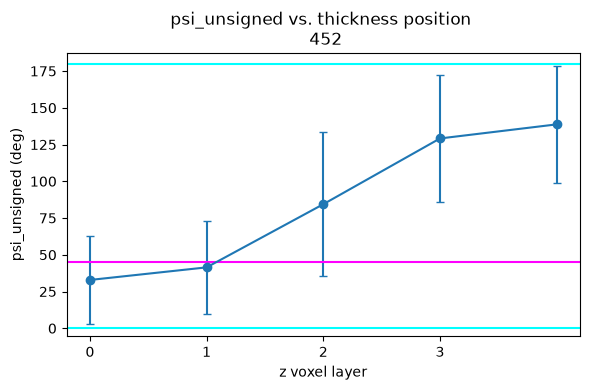

74386 / 74386 vertices fall within layers 0-4
[-45, 45]


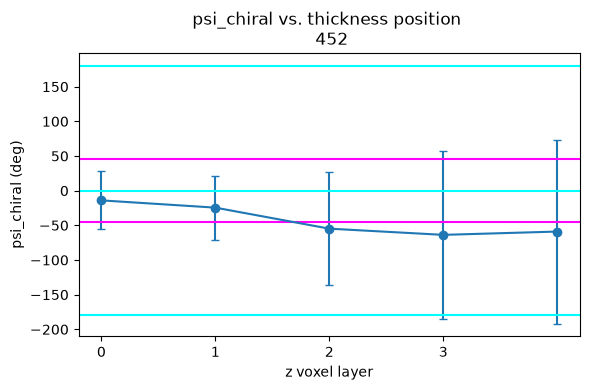

74386 / 74386 vertices fall within layers 0-4
[0]


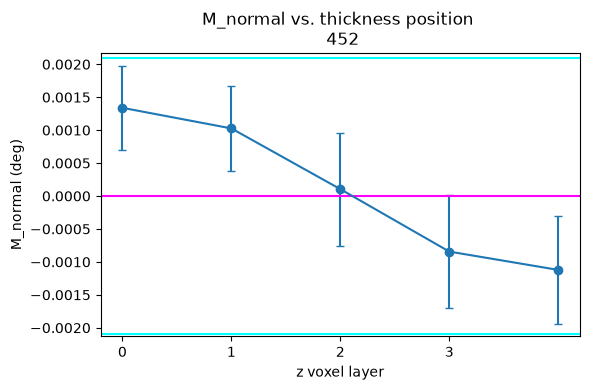

,mean,std,count
z_layer,,,
0,0.001339,0.000636,13750
1,0.001027,0.000649,14361
2,0.000105,0.000858,22971
3,-0.000843,0.000854,14257
4,-0.001121,0.000815,9047


In [ ]:
bounds = [0,int(volume['shape'][0])//4]
plot_angle_vs_z(wall_df, bounds,angle_col='psi_unsigned',  bloch_axis = [45] , neel_axis = [0, 180], title = sample_name )
plot_angle_vs_z(wall_df,bounds, angle_col='psi_chiral', bloch_axis = [-45, 45] , neel_axis = [-180, 0, 180], title = sample_name)
plot_angle_vs_z(wall_df,bounds, angle_col='M_normal', bloch_axis = [0] , neel_axis = [np.min(Mz), np.max(Mz)], title = sample_name )



74386 / 74386 vertices fall within layers 0-4
no axis


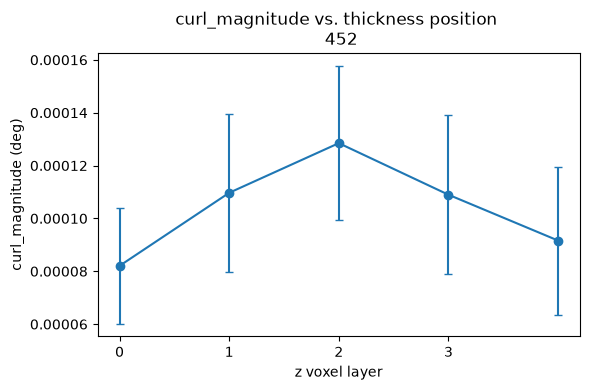

74386 / 74386 vertices fall within layers 0-4
no axis


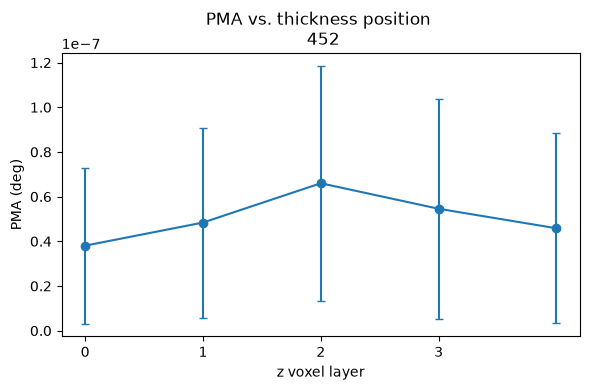

74386 / 74386 vertices fall within layers 0-4
no axis


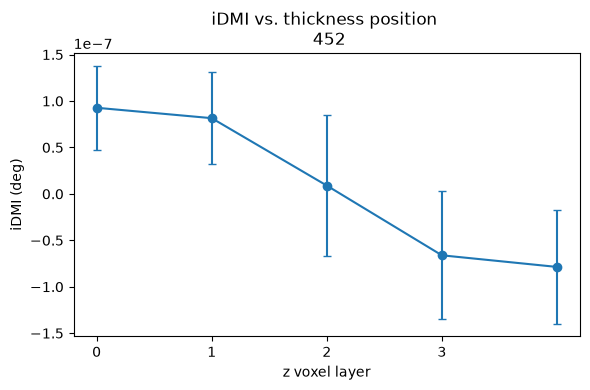

,mean,std,count
z_layer,,,
0,9.270857e-08,4.509041e-08,13750
1,8.151536e-08,4.974401e-08,14361
2,8.921383e-09,7.582660e-08,22971
3,-6.615179e-08,6.883727e-08,14257
4,-7.866298e-08,6.102654e-08,9047


In [ ]:
plot_angle_vs_z(wall_df, bounds,angle_col='curl_magnitude', title = sample_name )
plot_angle_vs_z(wall_df,bounds, angle_col='PMA',  title = sample_name)
plot_angle_vs_z(wall_df,bounds, angle_col='iDMI', title = sample_name )

# highlight Bloch and Neel

In [ ]:
def classify_pure_bloch_neel(wall_df, method='normal', tol=None, z_offset_included=True):
    """
    Classify wall vertices as 'bloch', 'neel', or 'unclassified' using one
    of two strict criteria.

    Parameters
    ----------
    wall_df : pd.DataFrame
        Must contain Mx, My, Mz, nx, ny, nz (and ix, iy, iz / x, y, z for
        location bookkeeping).
    method : 'normal' or 'psi'
        'normal' -- classify using M_n = M.n_hat directly.
            Bloch: |M_n| < tol           (tangential, no normal component)
            Neel:  |M_n| within tol of |M| (fully radial/along normal)
        'psi' -- classify using the unsigned wall-type angle, computed in
            RADIANS directly from M_n and the tangential magnitude (not
            the pre-computed degree column, to avoid round-trip error).
            Bloch: |psi_rad - pi/2| < tol
            Neel:  psi_rad within tol of 0 or pi
    tol : float
        Tolerance for the chosen method. Recommended: 0.0005 for 'normal'
        (dimensionless, dot-product units), 0.005 for 'psi' (radians).
    z_offset_included : bool
        Set True if wall_df['iz'] already reflects true experimental
        voxel numbering (as it should if you applied z_offset earlier).
        This is just a bookkeeping flag/reminder, not used in the math.

    Returns
    -------
    df : pd.DataFrame
        Copy of wall_df with an added 'category' column
        ('bloch' / 'neel' / 'unclassified') and the raw comparison
        quantity used (M_n and mag, or psi_rad) as new columns.
    """
    df = wall_df.copy()
    Mx, My, Mz = df['Mx'].values, df['My'].values, df['Mz'].values
    nx_, ny_, nz_ = df['nx'].values, df['ny'].values, df['nz'].values
    M_v = np.stack([Mx, My, Mz], axis=1)
    n_v = np.stack([nx_, ny_, nz_], axis=1)

    M_n = np.einsum('ij,ij->i', M_v, n_v)
    mag_v = np.linalg.norm(M_v, axis=1)

    category = np.full(len(df), 'unclassified', dtype=object)

    if method == 'normal':
        tol = 0.0005 if tol is None else tol
        is_bloch = np.abs(M_n) < tol
        is_neel = np.abs(np.abs(M_n) - mag_v) < tol
        df['M_n'] = M_n
        df['mag'] = mag_v

    elif method == 'psi':
        tol = 0.005 if tol is None else tol
        M_t_vec = M_v - M_n[:, None] * n_v
        M_t_mag = np.linalg.norm(M_t_vec, axis=1)
        psi_rad = np.arctan2(M_t_mag, M_n)  # range [0, pi]
        is_bloch = np.abs(psi_rad - np.pi / 2) < tol
        is_neel = (np.abs(psi_rad - 0.0) < tol) | (np.abs(psi_rad - np.pi) < tol)
        df['psi_rad'] = psi_rad

    else:
        raise ValueError("method must be 'normal' or 'psi'")

    category[is_bloch] = 'bloch'
    category[is_neel] = 'neel'
    overlap = is_bloch & is_neel
    if overlap.any():
        print(f"Warning: {overlap.sum()} vertices satisfied both criteria "
              f"simultaneously (tol may be too loose, or |M| is near zero "
              f"there); labeled as 'bloch' by default overwrite order.")

    df['category'] = category
    n_bloch, n_neel = (category == 'bloch').sum(), (category == 'neel').sum()
    print(f"[{method}] tol={tol}: {n_bloch} bloch, {n_neel} neel, "
          f"{len(df) - n_bloch - n_neel} unclassified (of {len(df)} total)")

    return df

In [ ]:
def plot_pure_bloch_neel_3d(mesh_verts_xyz, classified_df,
                             bloch_color='magenta', neel_color='cyan',
                             show_unclassified=True, point_size=6):
    """
    3D PyVista scatter of classified wall vertices.
    mesh_verts_xyz : (N, 3) array matching classified_df row order
        (i.e. the same verts_xyz used to build wall_df originally).
    """
    plotter = pv.Plotter()

    is_bloch = (classified_df['category'] == 'bloch').values
    is_neel = (classified_df['category'] == 'neel').values
    is_other = ~(is_bloch | is_neel)

    if show_unclassified and is_other.any():
        plotter.add_points(mesh_verts_xyz[is_other], color='lightgray',
                            point_size=point_size * 0.5, opacity=0.15,
                            render_points_as_spheres=True)

    if is_bloch.any():
        plotter.add_points(mesh_verts_xyz[is_bloch], color=bloch_color,
                            point_size=point_size, render_points_as_spheres=True,
                            label='Bloch (pure)')
    if is_neel.any():
        plotter.add_points(mesh_verts_xyz[is_neel], color=neel_color,
                            point_size=point_size, render_points_as_spheres=True,
                            label='Neel (pure)')

    plotter.add_legend()
    plotter.add_axes()
    plotter.show()

In [ ]:
def extract_pure_locations(classified_df):
    """
    Pull out (x, y, z) physical coords and iz (true experimental voxel
    layer) for bloch and neel vertices separately.
    """
    cols = ['x', 'y', 'z', 'ix', 'iy', 'iz']
    bloch_locs = classified_df[classified_df['category'] == 'bloch'][cols].copy()
    neel_locs = classified_df[classified_df['category'] == 'neel'][cols].copy()
    return bloch_locs, neel_locs

[normal] tol=5e-05: 1389 bloch, 16149 neel, 56848 unclassified (of 74386 total)
[psi] tol=0.1: 2592 bloch, 4134 neel, 67660 unclassified (of 74386 total)


C:\Users\emmab\AppData\Local\Temp\ipykernel_2824\2151229276.py:31: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


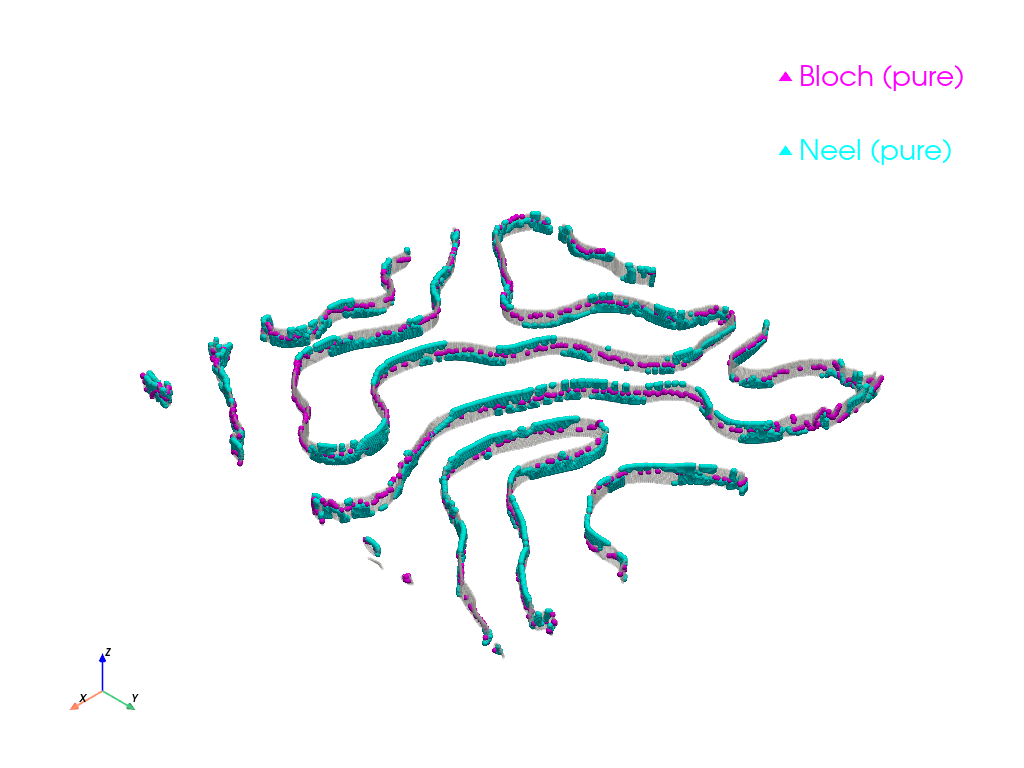

C:\Users\emmab\AppData\Local\Temp\ipykernel_2824\2151229276.py:31: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


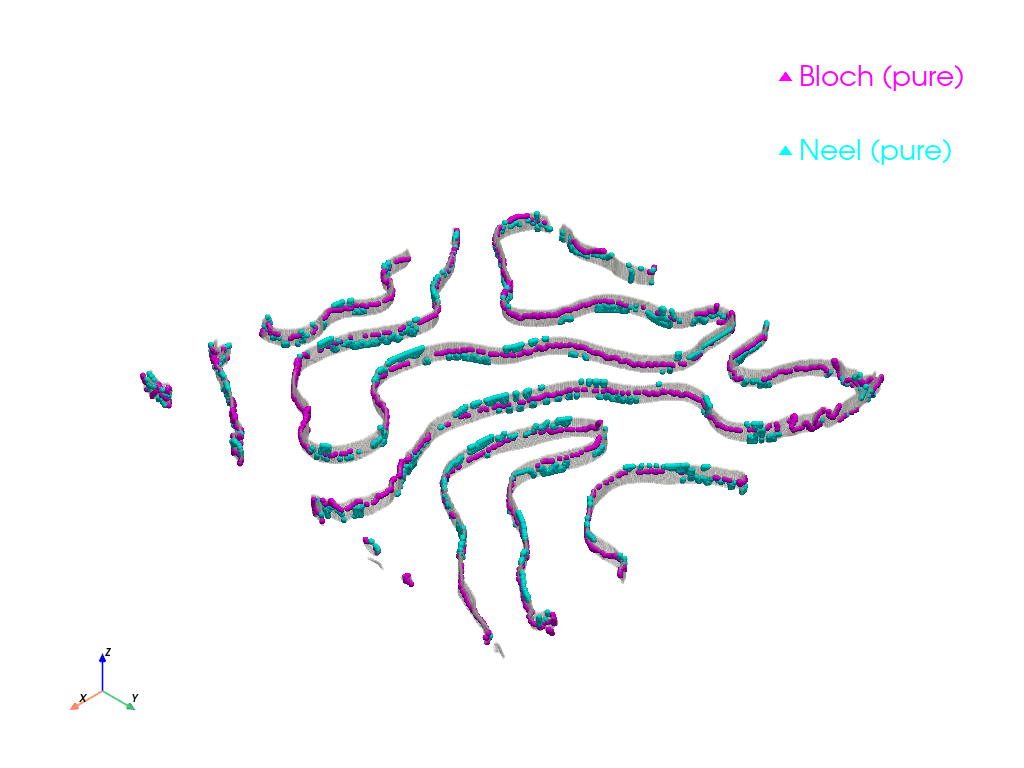

In [ ]:
classified_normal = classify_pure_bloch_neel(wall_df, method='normal', tol=0.00005)
bloch_normal_locs, neel_normal_locs = extract_pure_locations(classified_normal)

classified_psi = classify_pure_bloch_neel(wall_df, method='psi', tol=0.1)
bloch_psi_locs, neel_psi_locs = extract_pure_locations(classified_psi)

plot_pure_bloch_neel_3d(verts_xyz, classified_normal)
plot_pure_bloch_neel_3d(verts_xyz, classified_psi)

In [ ]:


def compute_arclength_per_layer(wall_df, z_bin_size=1.0):
    """
    For each z-layer, order the wall vertices along their in-plane (x, y)
    trace and assign an arc-length coordinate s. Returns wall_df with an
    added 's' column (NaN where a layer has too few points to order).
    """
    df = wall_df.copy()
    df['z_bin'] = (df['z'] / z_bin_size).round() * z_bin_size
    df['s'] = np.nan

    for z_val, group in df.groupby('z_bin'):
        if len(group) < 3:
            continue
        pts = group[['x', 'y']].values
        centroid = pts.mean(axis=0)
        angles = np.arctan2(pts[:, 1] - centroid[1], pts[:, 0] - centroid[0])
        order = np.argsort(angles)  # crude ordering; fine for a single closed/simple wall trace
        ordered_idx = group.index.values[order]
        ordered_pts = pts[order]
        seg_lengths = np.linalg.norm(np.diff(ordered_pts, axis=0), axis=1)
        s_vals = np.concatenate([[0], np.cumsum(seg_lengths)])
        df.loc[ordered_idx, 's'] = s_vals

    return df

def plot_unrolled_wall(wall_df, angle_col='psi_chiral', z_bin_size=1.0, cmap='twilight'):
    df = compute_arclength_per_layer(wall_df, z_bin_size)
    fig, ax = plt.subplots(figsize=(8, 5))
    sc = ax.scatter(df['s'], df['z'], c=df[angle_col], cmap=cmap,
                     vmin=-180 if 'chiral' in angle_col else 0,
                     vmax=180, s=15)
    fig.colorbar(sc, ax=ax, label=f'{angle_col} (deg)')
    ax.set_xlabel('arc length along wall, s (nm)')
    ax.set_ylabel('z (nm, thickness)')
    ax.set_title(f'Unrolled wall: {angle_col}')
    plt.tight_layout()
    plt.show()
    return df


def plot_slice_with_wall_overlay(sample, wall_df, field='Mz', axis='z', index=None,
                                  angle_col='psi_chiral', spacing=(8.0, 8.0, 8.0),
                                  tol=4.0, cmap_field='viridis', cmap_angle='seismic'):
    """
    Plot a 2D voxel slice (matching plot_three_slice conventions) with an
    overlay of wall_df points lying within `tol` (physical units) of that
    slice plane, colored by angle_col.
    """
    field_aliases = {'mag': 'magnitude', 'magnitude': 'magnitude',
                      'mx': 'Mx', 'my': 'My', 'mz': 'Mz'}
    key = field_aliases.get(field.lower())
    data = sample[key]
    nz, ny, nx = sample['shape']
    dz, dy, dx = spacing

    default_index = {'x': nx // 2, 'y': ny // 2, 'z': nz // 2}
    if index is None:
        index = default_index[axis]

    axis_col = {'x': 'x', 'y': 'y', 'z': 'z'}[axis]
    slice_spacing = {'x': dx, 'y': dy, 'z': dz}[axis]
    slice_phys = index * slice_spacing

    if axis == 'z':
        img = data[index, :, :]; extent = [0, nx * dx, 0, ny * dy]
        px_col, py_col = 'x', 'y'
    elif axis == 'y':
        img = data[:, index, :]; extent = [0, nx * dx, 0, nz * dz]
        px_col, py_col = 'x', 'z'
    else:  # 'x'
        img = data[:, :, index]; extent = [0, ny * dy, 0, nz * dz]
        px_col, py_col = 'y', 'z'

    nearby = wall_df[np.abs(wall_df[axis_col] - slice_phys) < tol]

    fig, ax = plt.subplots(figsize=(10, 7))
    im = ax.imshow(img, origin='lower', extent=extent, cmap=cmap_field,
                    vmin=np.nanmin(data), vmax=np.nanmax(data), aspect='auto')
    fig.colorbar(im, ax=ax, label=key)

    if len(nearby) > 0:
        sc = ax.scatter(nearby[px_col], nearby[py_col], c=nearby[angle_col],
                         cmap=cmap_angle,
                         vmin=np.min(wall_df[angle_col]), vmax=np.max(wall_df[angle_col]),
                         s=25, edgecolors='k', linewidths=0.3)
        fig.colorbar(sc, ax=ax, label=f'{angle_col} (deg)', pad=0.12)

    ax.set_title(f'{key} slice ({axis}={index}) with wall {angle_col} overlay\n'
                 f'({len(nearby)} wall points within {tol} nm of slice)')
    ax.set_xlabel(px_col); ax.set_ylabel(py_col)
    plt.tight_layout()
    plt.show()
    return nearby

In [ ]:
plot_slice_with_wall_overlay(samples[sample_name]['cropped'], wall_df, field='Mx', axis='z', index=None,
                                  angle_col='M_normal', spacing=(8.0, 8.0, 8.0),
                                  tol=4.0, cmap_field='viridis', cmap_angle='seismic')

NameError: name 'samples' is not defined

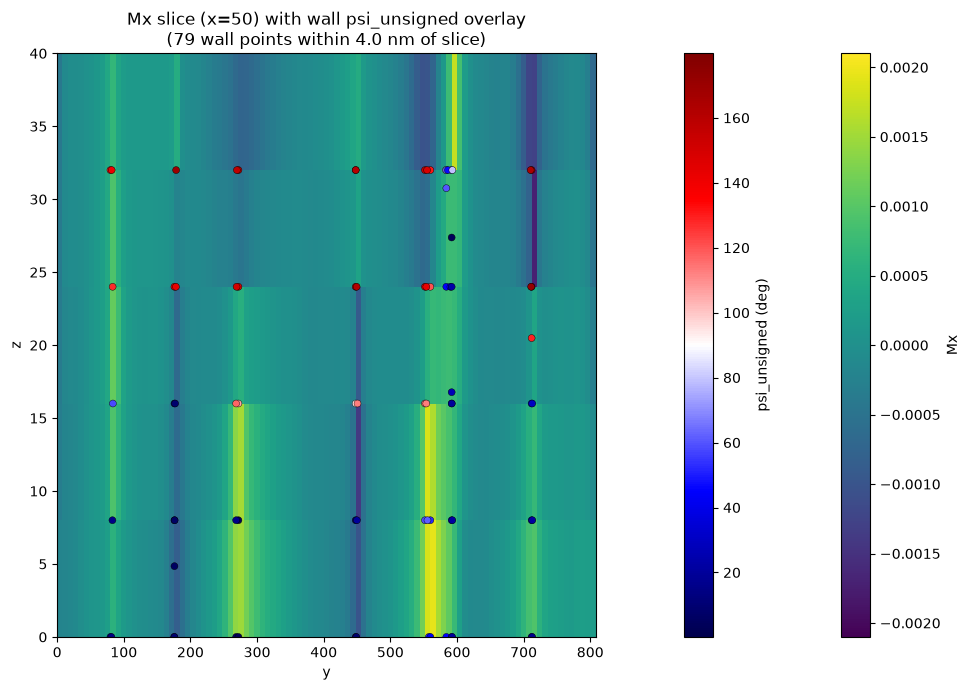

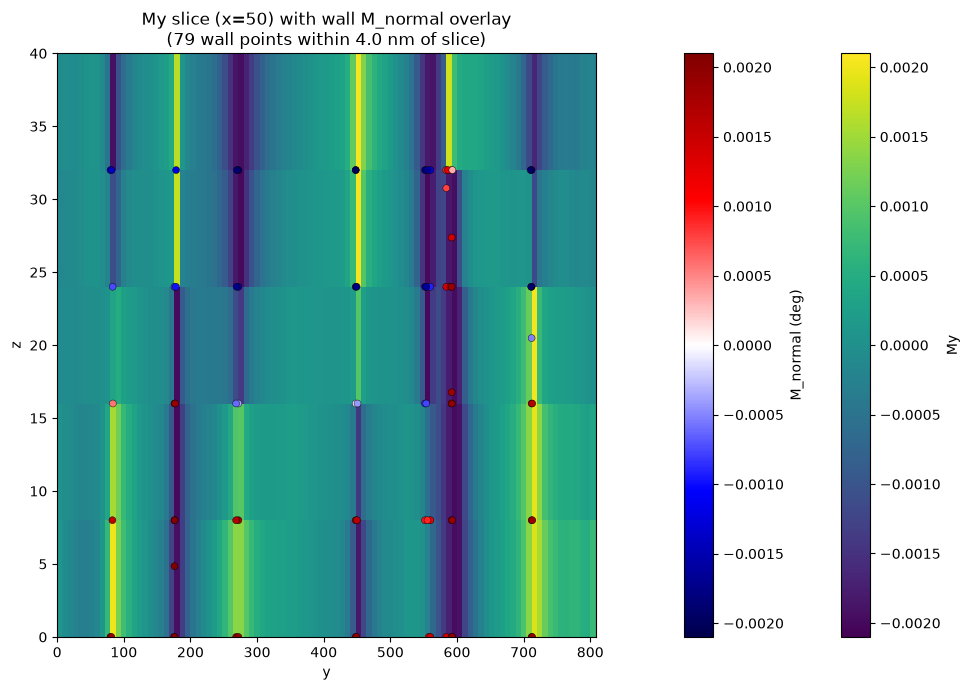

,x,y,z,ix,iy,iz,nx,ny,nz,tx,ty,tz,Mx,My,Mz,M_normal,psi_unsigned,psi_chiral,degenerate,vertex_id
300,402.948944,80.000000,0.000000,50.368618,10.000000,0.000000,0.439225,0.869330,-0.226600,-0.892547,0.450955,0.0,0.000647,0.001930,0.000063,0.001948,16.981049,8.562410,False,300
325,400.000000,81.403366,0.000000,50.000000,10.175421,0.000000,0.336982,0.914388,-0.224361,-0.938309,0.345798,0.0,0.000557,0.001859,0.000020,0.001883,14.004601,3.653698,False,325
326,400.000000,82.942162,8.000000,50.000000,10.367770,1.000000,0.253583,0.958335,-0.131488,-0.966729,0.255804,0.0,0.000811,0.001414,-0.000093,0.001573,15.562946,-15.043968,False,326
550,400.000000,175.554733,0.000000,50.000000,21.944342,0.000000,-0.274702,-0.960795,0.037570,0.961474,-0.274896,0.0,-0.000813,-0.001887,-0.000048,0.002035,8.135459,-7.367253,False,550
551,400.000000,176.000000,4.851561,50.000000,22.000000,0.606445,-0.335649,-0.938488,0.081115,0.941591,-0.336758,0.0,-0.000712,-0.001971,-0.000028,0.002087,5.410549,-0.180377,False,551
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5386,400.000000,592.000000,27.378098,50.000000,74.000000,3.422262,0.774422,-0.608914,0.171740,0.618098,0.786101,-0.0,0.001171,-0.000796,0.000231,0.001431,3.972991,3.926611,False,5386
5387,400.000000,586.417847,32.000000,50.000000,73.302231,4.000000,0.954455,0.116098,-0.274841,-0.120748,0.992683,0.0,0.001065,0.001490,-0.000261,0.001261,47.024005,46.961332,False,5387
5410,400.000000,593.088928,32.000000,50.000000,74.136116,4.000000,0.538283,-0.828797,0.152795,0.838645,0.544679,-0.0,0.001620,0.000735,0.000516,0.000342,79.367705,79.004545,False,5410
5550,398.551819,712.000000,32.000000,49.818977,89.000000,4.000000,0.784458,0.603409,0.143257,-0.609698,0.792634,0.0,-0.001232,-0.001589,0.000013,-0.001924,163.055058,-165.197663,False,5550


In [ ]:
plot_slice_with_wall_overlay(samples[sample_name]['cropped'], wall_df, field='Mx', axis='x', index=None,
                                  angle_col='psi_unsigned', spacing=(8.0, 8.0, 8.0),
                                  tol=4.0, cmap_field='viridis', cmap_angle='seismic')

plot_slice_with_wall_overlay(samples[sample_name]['cropped'], wall_df, field='My', axis='x', index=None,
                                  angle_col='M_normal', spacing=(8.0, 8.0, 8.0),
                                  tol=4.0, cmap_field='viridis', cmap_angle='seismic')

# compare interpolated data

In [ ]:
def compare_interpolation_effect(classified_df, Mx_vol, My_vol, Mz_vol,
                                  method='normal', tol=None):
    """
    Compare Bloch/Neel classification using trilinear-interpolated M
    (the standard pipeline) against nearest-neighbor voxel M (no
    interpolation), to quantify how much interpolation is influencing
    the classification near strict tolerance boundaries.

    Parameters
    ----------
    classified_df : pd.DataFrame
        Output of classify_pure_bloch_neel, must contain ix, iy, iz
        (fractional voxel indices), nx, ny, nz (normal components),
        and 'category' (the interpolation-based classification).
    Mx_vol, My_vol, Mz_vol : ndarray, shape (nz, ny, nx)
        The raw (or smoothed, whichever was used upstream) voxel volumes.
    method, tol : same meaning as in classify_pure_bloch_neel; must match
        whatever was used to produce classified_df['category'], so the
        two classifications are directly comparable.

    Returns
    -------
    df : pd.DataFrame
        classified_df with added columns for the nearest-neighbor M,
        the nearest-neighbor category ('category_nn'), and a boolean
        'agrees' flag.
    """
    df = classified_df.copy()
    nz, ny, nx = Mz_vol.shape

    # Round fractional indices to nearest integer voxel, clip to valid range
    iz_nn = np.clip(df['iz'].round().astype(int), 0, nz - 1)
    iy_nn = np.clip(df['iy'].round().astype(int), 0, ny - 1)
    ix_nn = np.clip(df['ix'].round().astype(int), 0, nx - 1)

    Mx_nn = Mx_vol[iz_nn, iy_nn, ix_nn]
    My_nn = My_vol[iz_nn, iy_nn, ix_nn]
    Mz_nn = Mz_vol[iz_nn, iy_nn, ix_nn]
    M_nn = np.stack([Mx_nn, My_nn, Mz_nn], axis=1)

    n_v = df[['nx', 'ny', 'nz']].values  # reuse existing normals; only M sampling changes
    M_n_nn = np.einsum('ij,ij->i', M_nn, n_v)
    mag_nn = np.linalg.norm(M_nn, axis=1)

    category_nn = np.full(len(df), 'unclassified', dtype=object)

    if method == 'normal':
        tol = 0.0005 if tol is None else tol
        is_bloch = np.abs(M_n_nn) < tol
        is_neel = np.abs(np.abs(M_n_nn) - mag_nn) < tol
        df['M_n_nn'] = M_n_nn

    elif method == 'psi':
        tol = 0.005 if tol is None else tol
        M_t_vec_nn = M_nn - M_n_nn[:, None] * n_v
        M_t_mag_nn = np.linalg.norm(M_t_vec_nn, axis=1)
        psi_rad_nn = np.arctan2(M_t_mag_nn, M_n_nn)
        is_bloch = np.abs(psi_rad_nn - np.pi / 2) < tol
        is_neel = (np.abs(psi_rad_nn - 0.0) < tol) | (np.abs(psi_rad_nn - np.pi) < tol)
        df['psi_rad_nn'] = psi_rad_nn

    else:
        raise ValueError("method must be 'normal' or 'psi'")

    category_nn[is_bloch] = 'bloch'
    category_nn[is_neel] = 'neel'
    df['Mx_nn'], df['My_nn'], df['Mz_nn'] = Mx_nn, My_nn, Mz_nn
    df['category_nn'] = category_nn
    df['agrees'] = df['category'] == df['category_nn']

    # --- Summary ---
    n_total = len(df)
    n_agree = df['agrees'].sum()
    print(f"[{method}] Agreement: {n_agree} / {n_total} "
          f"({100 * n_agree / n_total:.1f}%)")

    confusion = pd.crosstab(df['category'], df['category_nn'],
                             rownames=['interpolated'], colnames=['nearest-neighbor'])
    print("\nConfusion matrix (interpolated vs. nearest-neighbor):")
    print(confusion)

    # Flag cases that specifically flipped between a "pure" label and something else,
    # since these are the ones most likely to be interpolation artifacts.
    flips = df[~df['agrees'] & ((df['category'].isin(['bloch', 'neel'])) |
                                  (df['category_nn'].isin(['bloch', 'neel'])))]
    print(f"\n{len(flips)} vertices flipped in/out of a 'pure' label "
          f"due to interpolation vs. nearest-neighbor sampling.")

    return df

In [ ]:
def plot_interpolation_mismatch(df, spacing=(8.0, 8.0, 8.0)):
    """
    Two-panel plot: (1) mismatch count per z-layer, (2) spatial map of
    mismatched vertices (x-y positions, colored by which category they
    flipped between).
    """
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    mismatch_by_layer = (~df['agrees']).groupby(df['iz'].round().astype(int)).sum()
    total_by_layer = df.groupby(df['iz'].round().astype(int)).size()
    frac_by_layer = mismatch_by_layer / total_by_layer

    axes[0].bar(frac_by_layer.index, frac_by_layer.values, color='tab:orange')
    axes[0].set_xlabel('z voxel layer')
    axes[0].set_ylabel('fraction mismatched')
    axes[0].set_title('Interpolation-driven classification disagreement by layer')

    mismatched = df[~df['agrees']]
    agree_pts = df[df['agrees']]
    axes[1].scatter(agree_pts['x'], agree_pts['y'], color='lightgray', s=5, alpha=0.3, label='agree')
    axes[1].scatter(mismatched['x'], mismatched['y'], color='red', s=15, label='mismatch')
    axes[1].set_xlabel('x (nm)')
    axes[1].set_ylabel('y (nm)')
    axes[1].set_title('Spatial location of mismatched vertices')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

In [ ]:
def plot_interpolation_mismatch(df, spacing=(8.0, 8.0, 8.0)):
    """
    Two-panel plot: (1) mismatch count per z-layer, (2) spatial map of
    mismatched vertices (x-y positions, colored by which category they
    flipped between).
    """
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    mismatch_by_layer = (~df['agrees']).groupby(df['iz'].round().astype(int)).sum()
    total_by_layer = df.groupby(df['iz'].round().astype(int)).size()
    frac_by_layer = mismatch_by_layer / total_by_layer

    axes[0].bar(frac_by_layer.index, frac_by_layer.values, color='tab:orange')
    axes[0].set_xlabel('z voxel layer')
    axes[0].set_ylabel('fraction mismatched')
    axes[0].set_title('Interpolation-driven classification disagreement by layer')

    mismatched = df[~df['agrees']]
    agree_pts = df[df['agrees']]
    axes[1].scatter(agree_pts['x'], agree_pts['y'], color='lightgray', s=5, alpha=0.3, label='agree')
    axes[1].scatter(mismatched['x'], mismatched['y'], color='red', s=15, label='mismatch')
    axes[1].set_xlabel('x (nm)')
    axes[1].set_ylabel('y (nm)')
    axes[1].set_title('Spatial location of mismatched vertices')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

[normal] tol=0.0005: 9268 bloch, 54332 neel, 10786 unclassified (of 74386 total)
[normal] Agreement: 11827 / 74386 (15.9%)

Confusion matrix (interpolated vs. nearest-neighbor):
nearest-neighbor  bloch  neel  unclassified
interpolated                               
bloch              6619   253          2396
neel              41031  2467         10834
unclassified       7796   249          2741

62559 vertices flipped in/out of a 'pure' label due to interpolation vs. nearest-neighbor sampling.


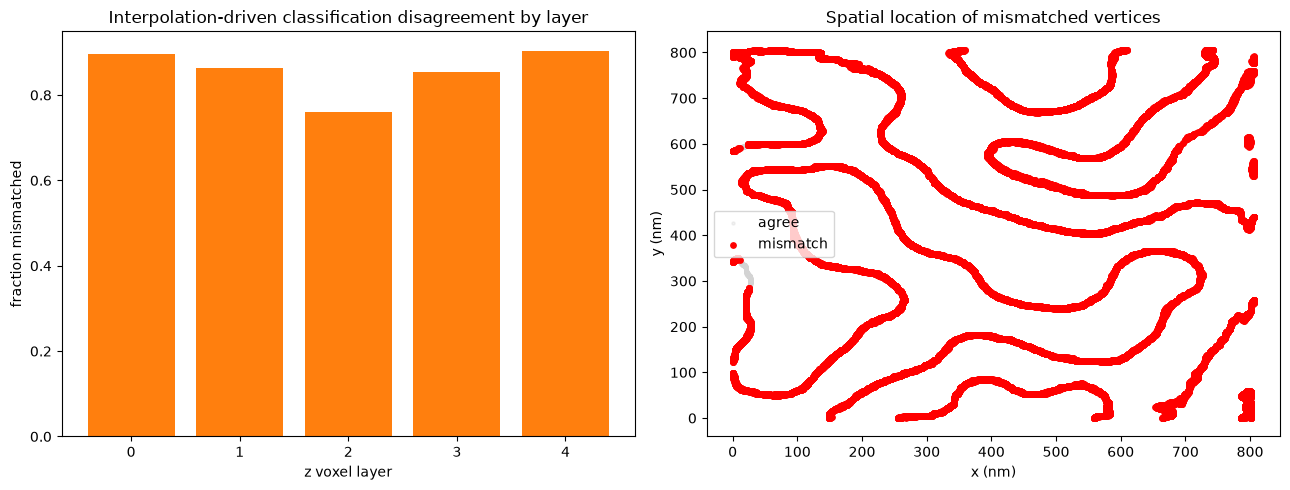

[psi] tol=0.005: 134 bloch, 12 neel, 74240 unclassified (of 74386 total)
[psi] Agreement: 72559 / 74386 (97.5%)

Confusion matrix (interpolated vs. nearest-neighbor):
nearest-neighbor  bloch  unclassified
interpolated                         
bloch                 3           131
neel                  0            12
unclassified       1684         72556

1827 vertices flipped in/out of a 'pure' label due to interpolation vs. nearest-neighbor sampling.


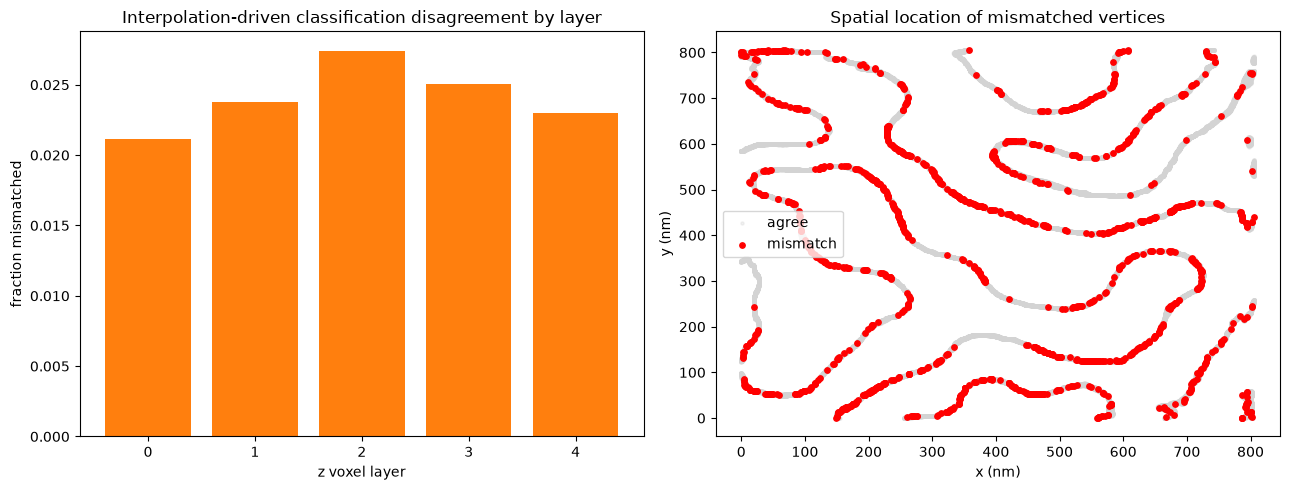

In [ ]:
classified_normal = classify_pure_bloch_neel(wall_df, method='normal', tol=0.0005)
comparison_normal = compare_interpolation_effect(classified_normal, Mx, My, Mz, method='normal', tol=0.0005)
plot_interpolation_mismatch(comparison_normal)

classified_psi = classify_pure_bloch_neel(wall_df, method='psi', tol=0.005)
comparison_psi = compare_interpolation_effect(classified_psi, Mx, My, Mz, method='psi', tol=0.005)
plot_interpolation_mismatch(comparison_psi)

# save data_frame

In [ ]:
stop

NameError: name 'stop' is not defined

In [148]:
def make_json_safe(obj):
    """
    Recursively convert numpy types within a nested dict/list/tuple
    structure into native Python types, so it can be safely passed to
    json.dump. Handles numpy ints, floats, bools, and arrays.
    """
    if isinstance(obj, dict):
        return {k: make_json_safe(v) for k, v in obj.items()}
    elif isinstance(obj, (list, tuple)):
        return [make_json_safe(v) for v in obj]
    elif isinstance(obj, np.ndarray):
        return obj.tolist()
    elif isinstance(obj, (np.integer,)):
        return int(obj)
    elif isinstance(obj, (np.floating,)):
        return float(obj)
    elif isinstance(obj, (np.bool_,)):
        return bool(obj)
    else:
        return obj

In [149]:
def save_sample_data(save_dir, sample_name, wall_df,
                      spacing=(2.0, 2.0, 2.0), z_offset=0, date = None,
                      extra_metadata=None):
    """
    Save the cropped volume and wall-analysis DataFrame for one sample,
    in a format suitable for later cross-sample/material comparison.

    Parameters
    ----------
    save_dir : str
        Directory to save into (created if it doesn't exist).
    sample_name : str
        Identifier for this sample/material, used in filenames and
        stamped into the saved data for later grouping.
    wall_df : pd.DataFrame
        The per-vertex wall analysis table (normals, psi, chirality, etc.)
    spacing : tuple
        (dz, dy, dx) physical voxel size, in nm.
    z_offset : int
        Offset applied to bring local z-indices back into the original
        volume's index frame (as discussed earlier).
    extra_metadata : dict or None
        Any additional key-value info you want stored alongside (e.g.
        material composition, deposition conditions, notes).
    """
    os.makedirs(save_dir, exist_ok=True)


    # --- Save wall_df, tagged with sample identity ---
    df_out = wall_df.copy()
    df_out['sample_name'] = sample_name
    df_path = os.path.join(save_dir, f'{sample_name}_wall_df_{date}.csv')
    df_out.to_csv(df_path, index=False)

    # --- Save human-readable metadata alongside, for provenance ---
    metadata = {
        'sample_name': sample_name,
        'spacing_nm': list(spacing),
        'z_offset': z_offset,
        'n_wall_vertices': len(wall_df),
        'volume_shape': list(volume['shape']),
    }

    if extra_metadata:
        metadata.update(extra_metadata)
    meta_path = os.path.join(save_dir, f'{sample_name}_wall_analysis_metadata_{date}.json')
    with open(meta_path, 'w') as f:
        json.dump(make_json_safe(metadata), f, indent=2)

    print(f"Saved: {df_path}\n       {meta_path}")
    return df_path, meta_path

In [ ]:
save_dir = data_dir

save_sample_data(save_dir, sample_name, wall_df, spacing=(2.0, 2.0, 2.0), z_offset=0, date = date, extra_metadata=None)

Saved: C:\Users\emmab\Projects\Vector_Tomography\data_dir\452_wall_df_14AUG26_interpolated.csv
       C:\Users\emmab\Projects\Vector_Tomography\data_dir\452_wall_analysis_metadata_14AUG26_interpolated.json


('C:\\Users\\emmab\\Projects\\Vector_Tomography\\data_dir\\452_wall_df_14AUG26_interpolated.csv',
 'C:\\Users\\emmab\\Projects\\Vector_Tomography\\data_dir\\452_wall_analysis_metadata_14AUG26_interpolated.json')

# Save for paraview

In [150]:
def export_wall_mesh_to_paraview(verts_xyz, faces, wall_df, save_path,
                                  scalar_cols=None, vector_col_groups=None):
    """
    Export the domain wall isosurface mesh, with all computed scalar and
    vector fields attached as point data, to a .vtp file readable
    directly in ParaView.

    Parameters
    ----------
    verts_xyz : (N, 3) array
        Mesh vertex coordinates, as produced by marching_cubes.
    faces : (M, 3) array
        Triangle connectivity, as produced by marching_cubes.
    wall_df : pd.DataFrame
        Per-vertex table (must have the same row order/length as
        verts_xyz) containing scalar and vector components to export.
    save_path : str
        Output file path, should end in '.vtp'.
    scalar_cols : list of str or None
        Column names in wall_df to attach as scalar point-data fields
        (e.g. ['psi_unsigned', 'psi_chiral', 'curl_magnitude',
        'dmi_interfacial']). If None, a sensible default set is used
        if present in wall_df.
    vector_col_groups : dict of {name: (x_col, y_col, z_col)} or None
        Named vector fields to attach, built from three wall_df columns
        each, e.g. {'Normal': ('nx','ny','nz'), 'Tangent': ('tx','ty','tz'),
        'M': ('Mx','My','Mz')}. If None, a sensible default set is used
        if present in wall_df.

    Returns
    -------
    mesh : pv.PolyData
        The mesh object that was saved, in case you want to inspect or
        further modify it in the same session.
    """
    faces_pv = np.hstack([np.full((faces.shape[0], 1), 3), faces]).astype(np.int64)
    mesh = pv.PolyData(verts_xyz, faces_pv)

    if scalar_cols is None:
        candidates = ['psi_unsigned', 'psi_chiral', 'curl_magnitude',
                      'dmi_interfacial', 'divergence', 'category']
        scalar_cols = [c for c in candidates if c in wall_df.columns]

    if vector_col_groups is None:
        candidates = {
            'Normal': ('nx', 'ny', 'nz'),
            'Tangent': ('tx', 'ty', 'tz'),
            'M': ('Mx', 'My', 'Mz'),
        }
        vector_col_groups = {
            name: cols for name, cols in candidates.items()
            if all(c in wall_df.columns for c in cols)
        }

    for col in scalar_cols:
        values = wall_df[col].values
        if values.dtype == object:  # e.g. 'category' being string labels
            # ParaView can't handle string arrays as colorable scalars directly;
            # encode as integer codes instead, and keep a lookup printed for reference.
            codes, uniques = pd.factorize(values)
            mesh.point_data[f'{col}_code'] = codes.astype(np.float32)
            print(f"'{col}' is categorical; saved as '{col}_code' with mapping: "
                  f"{dict(enumerate(uniques))}")
        else:
            mesh.point_data[col] = values.astype(np.float32)

    for vec_name, (cx, cy, cz) in vector_col_groups.items():
        vec_array = wall_df[[cx, cy, cz]].values.astype(np.float32)
        mesh.point_data[vec_name] = vec_array

    mesh.save(save_path)
    print(f"Saved mesh with {mesh.n_points} points, {mesh.n_cells} cells to {save_path}")
    print(f"  Scalar fields: {[c for c in scalar_cols]}")
    print(f"  Vector fields: {list(vector_col_groups.keys())}")

    return mesh

In [ ]:

save_path = os.path.join(data_dir, f'{sample_name}_wall_mesh_{date}.vtp')

mesh = export_wall_mesh_to_paraview(
    verts_xyz, faces, wall_df,
    save_path=save_path,
    scalar_cols=['M_normal', 'psi_unsigned', 'psi_chiral', 'curl_magnitude', 'iDMI', 'Divergence', 'PMA', 'Nsk', 'Mx', 'My'],
    vector_col_groups={'Normal': ('nx', 'ny', 'nz'),
                        'Tangent': ('tx', 'ty', 'tz'),
                        'M': ('Mx', 'My', 'Mz')}
)

Saved mesh with 26731 points, 51284 cells to C:\Users\emmab\Projects\Vector_Tomography\data_dir\665_wall_mesh_22AUG26_interpolated.vtp
  Scalar fields: ['M_normal', 'psi_unsigned', 'psi_chiral', 'curl_magnitude', 'iDMI', 'Divergence', 'PMA', 'Nsk', 'Mx', 'My']
  Vector fields: ['Normal', 'Tangent', 'M']


In [151]:
save_path = os.path.join(data_dir, f'{sample_name}_div_wall_mesh_{date}.vtp')

div_mesh = export_wall_mesh_to_paraview(
    verts_xyz, faces, wall_df,
    save_path=save_path,
    scalar_cols=['div_M','source', 'sink'],
    vector_col_groups={'Normal': ('nx', 'ny', 'nz'),
                        'Tangent': ('tx', 'ty', 'tz'),
                        'M': ('Mx', 'My', 'Mz')}
)

Saved mesh with 74386 points, 139572 cells to C:\Users\emmab\Projects\Vector_Tomography\data_dir\452_div_wall_mesh_14AUG26_interpolated.vtp
  Scalar fields: ['div_M', 'source', 'sink']
  Vector fields: ['Normal', 'Tangent', 'M']


In [ ]:
stop

NameError: name 'stop' is not defined